In [1]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = data.data
y = data.target

feature_names = data.feature_names
target_names = data.target_names

In [ ]:
print("Tamaño de X:", X.shape)
print("Tamaño de y:", y.shape)
print("Clases:", target_names)
print("Características:", feature_names)

Tamaño de X: (569, 30)
Tamaño de y: (569,)
Clases: ['malignant' 'benign']
Características: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Datos originales:", X.shape)
print("Datos estandarizados:", X_scaled.shape)

Datos originales: (569, 30)
Datos estandarizados: (569, 30)


---

# Modelo 1: Clustering jerárquico

El modelo se entrenará utilizando las 30 características estandarizadas del conjunto de cáncer de mama.

Se probarán diferentes números de clústeres, métodos de enlace y métricas de distancia. La mejor configuración se seleccionará mediante el coeficiente de silueta.

Las etiquetas reales no se utilizarán durante el entrenamiento; solamente servirán posteriormente para interpretar los grupos obtenidos.

---

In [ ]:
resultados_jerarquico = []

configuraciones = [
    ("ward", "euclidean"),
    ("complete", "euclidean"),
    ("complete", "manhattan"),
    ("complete", "cosine"),
    ("average", "euclidean"),
    ("average", "manhattan"),
    ("average", "cosine"),
    ("single", "euclidean"),
    ("single", "manhattan"),
    ("single", "cosine")
]

for linkage_method, distance_metric in configuraciones:
    for n_clusters in range(2, 7):

        modelo = AgglomerativeClustering(
            n_clusters=n_clusters,
            linkage=linkage_method,
            metric=distance_metric
        )

        etiquetas_cluster = modelo.fit_predict(X_scaled)

        silueta = silhouette_score(
            X_scaled,
            etiquetas_cluster,
            metric=distance_metric
        )

        resultados_jerarquico.append({
            "linkage": linkage_method,
            "metrica": distance_metric,
            "n_clusters": n_clusters,
            "silueta": silueta
        })

resultados_df = pd.DataFrame(resultados_jerarquico)

resultados_df = resultados_df.sort_values(
    by="silueta",
    ascending=False
).reset_index(drop=True)

resultados_df.head(10)

,linkage,metrica,n_clusters,silueta
0,complete,euclidean,2,0.660667
1,single,euclidean,2,0.660667
2,single,euclidean,3,0.635586
3,average,euclidean,2,0.633978
4,average,manhattan,2,0.612230
5,single,manhattan,2,0.612230
6,single,manhattan,3,0.591236
7,average,euclidean,3,0.584587
8,average,euclidean,4,0.554311
9,complete,euclidean,3,0.545047


## Selección de la mejor configuración

Aunque las configuraciones complete-euclidean y single-euclidean obtuvieron la mayor silueta, ambas dividieron los datos en grupos de 567 y 2 muestras. Esto indica que solamente aislaron dos observaciones extremas, por lo que no representan una agrupación útil del conjunto de datos.

Por esta razón, se seleccionó la configuración con enlace **average**, distancia **cosine** y **2 clústeres**. Esta obtuvo una silueta de **0.468734** y formó grupos de **378 y 191 muestras**, proporcionando una distribución más razonable e interpretable.

In [ ]:
mejor_modelo_jerarquico = AgglomerativeClustering(
    n_clusters=2,
    linkage="average",
    metric="cosine",
    compute_distances=True
)

clusters_jerarquico = mejor_modelo_jerarquico.fit_predict(X_scaled)

valores, cantidades = np.unique(
    clusters_jerarquico,
    return_counts=True
)

print("Clústeres:", valores)
print("Cantidad de muestras por clúster:", cantidades)

Clústeres: [0 1]
Cantidad de muestras por clúster: [378 191]


## Dendrograma del clustering jerárquico

El dendrograma representa cómo las muestras se fusionan progresivamente para formar los clústeres. Se utiliza la configuración final con enlace average y distancia coseno. La línea horizontal representa el corte del árbol que produce los dos clústeres seleccionados.

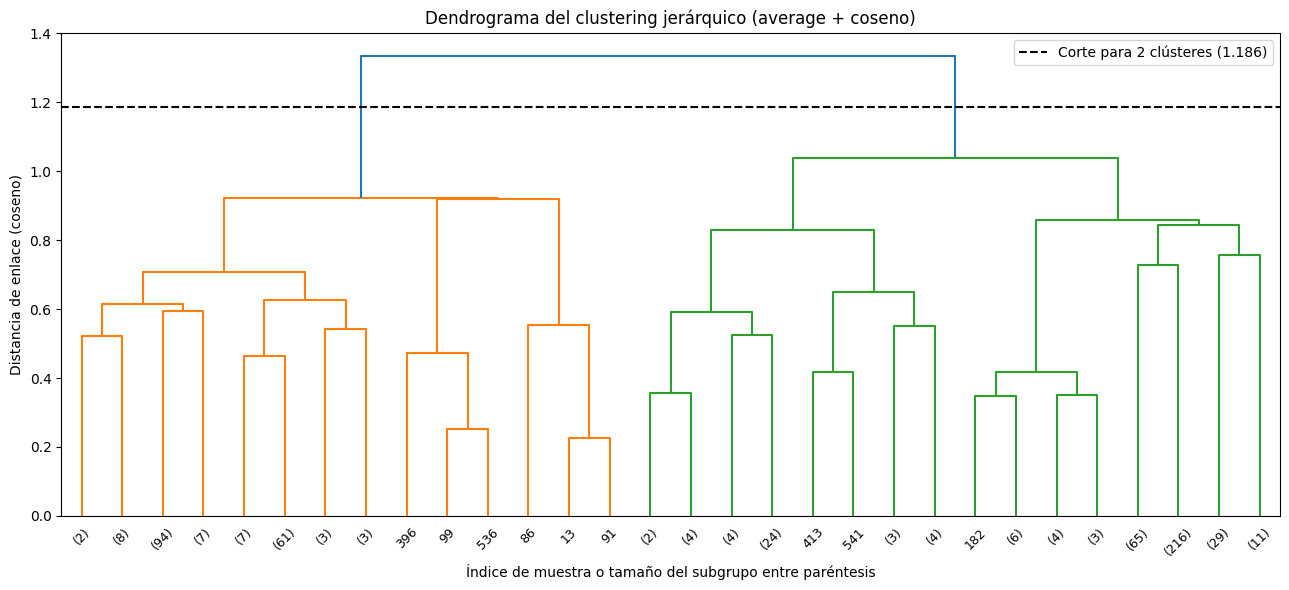

In [ ]:
from scipy.cluster.hierarchy import dendrogram

def matriz_para_dendrograma(modelo):
    n_muestras = len(modelo.labels_)
    tamanos = np.zeros(len(modelo.children_), dtype=int)

    for i, hijos in enumerate(modelo.children_):
        for hijo in hijos:
            if hijo < n_muestras:
                tamanos[i] += 1
            else:
                tamanos[i] += tamanos[hijo - n_muestras]

    matriz = np.column_stack([
        modelo.children_,
        modelo.distances_,
        tamanos
    ]).astype(float)

    return matriz


matriz_jerarquica = matriz_para_dendrograma(
    mejor_modelo_jerarquico
)

corte_jerarquico = matriz_jerarquica[-2:, 2].mean()

fig, ax = plt.subplots(figsize=(13, 6))

dendrogram(
    matriz_jerarquica,
    truncate_mode="level",
    p=4,
    leaf_font_size=9,
    color_threshold=corte_jerarquico,
    ax=ax
)

ax.axhline(
    y=corte_jerarquico,
    color="black",
    linestyle="--",
    label=f"Corte para 2 clústeres ({corte_jerarquico:.3f})"
)

ax.set_title(
    "Dendrograma del clustering jerárquico (average + coseno)"
)

ax.set_xlabel(
    "Índice de muestra o tamaño del subgrupo entre paréntesis"
)

ax.set_ylabel("Distancia de enlace (coseno)")
ax.legend()

plt.tight_layout()
plt.show()

### Interpretación del dendrograma

El dendrograma representa el proceso de agrupamiento de las muestras mediante enlace **average** y distancia **coseno**. Al realizar un corte aproximado en una distancia de **1.186**, el árbol queda dividido en dos ramas principales, correspondientes a los dos clústeres seleccionados.

La gráfica se presenta de forma truncada para facilitar su lectura; los valores entre paréntesis indican la cantidad de observaciones contenidas en cada subgrupo. El modelo fue ajustado utilizando las 30 características estandarizadas del conjunto de datos. PCA se utilizó posteriormente solo para la visualización bidimensional.

## Visualización de los clústeres con PCA

Para visualizar los resultados, las 30 características estandarizadas se redujeron a dos componentes principales mediante PCA. Esta reducción se utiliza únicamente para representar gráficamente los clústeres y no para entrenar el modelo.

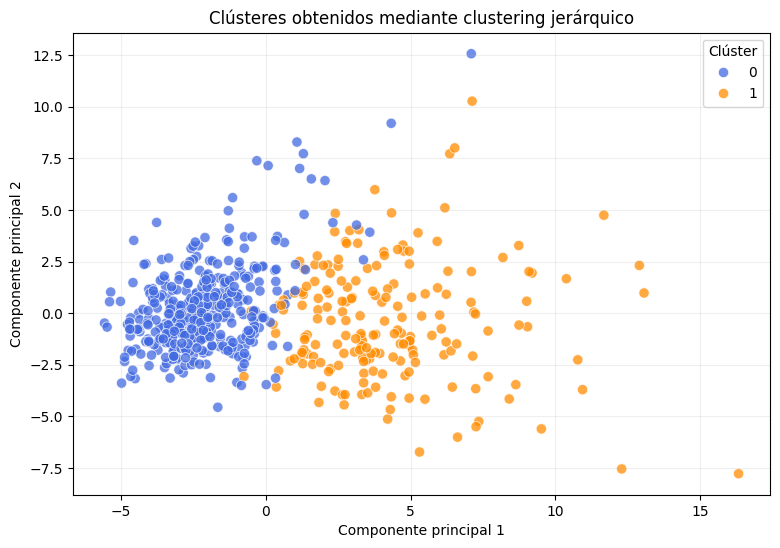

Varianza explicada por los dos componentes: 0.6324320765155944


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=clusters_jerarquico,
    palette=["royalblue", "darkorange"],
    alpha=0.75,
    s=55
)

plt.title("Clústeres obtenidos mediante clustering jerárquico")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Clúster")
plt.grid(alpha=0.2)
plt.show()

print(
    "Varianza explicada por los dos componentes:",
    pca.explained_variance_ratio_.sum()
)

### Interpretación de la visualización

La proyección mediante PCA muestra una separación visible entre los dos clústeres, principalmente a lo largo del primer componente principal. El clúster 0 se concentra mayormente en la región izquierda, mientras que el clúster 1 se distribuye hacia la región derecha.

Existe cierto traslape entre ambos grupos en la zona central, lo que indica que algunas muestras presentan características similares. Sin embargo, la distribución general muestra que el clustering jerárquico logró identificar dos grupos diferenciados.

PCA se utilizó únicamente para la visualización; el modelo fue entrenado utilizando las 30 características estandarizadas.

In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

comparacion_jerarquico = pd.DataFrame({
    "Cluster": clusters_jerarquico,
    "Diagnóstico real": data.target_names[y]
})

tabla_comparacion = pd.crosstab(
    comparacion_jerarquico["Cluster"],
    comparacion_jerarquico["Diagnóstico real"]
)

ari_jerarquico = adjusted_rand_score(
    y,
    clusters_jerarquico
)

nmi_jerarquico = normalized_mutual_info_score(
    y,
    clusters_jerarquico
)

print("Comparación entre clústeres y diagnósticos reales:")
display(tabla_comparacion)

print("Índice Rand ajustado:", ari_jerarquico)
print("Información mutua normalizada:", nmi_jerarquico)

Comparación entre clústeres y diagnósticos reales:


Diagnóstico real,benign,malignant
Cluster,,
0,351,27
1,6,185


Índice Rand ajustado: 0.779598877208407
Información mutua normalizada: 0.6815945697010094


### Evaluación frente a las etiquetas reales

El clúster 0 agrupó 351 muestras benignas y 27 malignas, mientras que el clúster 1 agrupó 185 muestras malignas y solamente 6 benignas. Por lo tanto, el clúster 0 presenta una fuerte correspondencia con los casos benignos y el clúster 1 con los casos malignos.

El índice Rand ajustado fue de 0.7796 y la información mutua normalizada fue de 0.6816. Estos resultados indican una correspondencia considerable entre los agrupamientos encontrados y los diagnósticos reales, a pesar de que las etiquetas no se utilizaron para entrenar el modelo.

El modelo no sustituye a un clasificador supervisado, pero demuestra que las características del conjunto contienen una estructura natural relacionada con el diagnóstico.

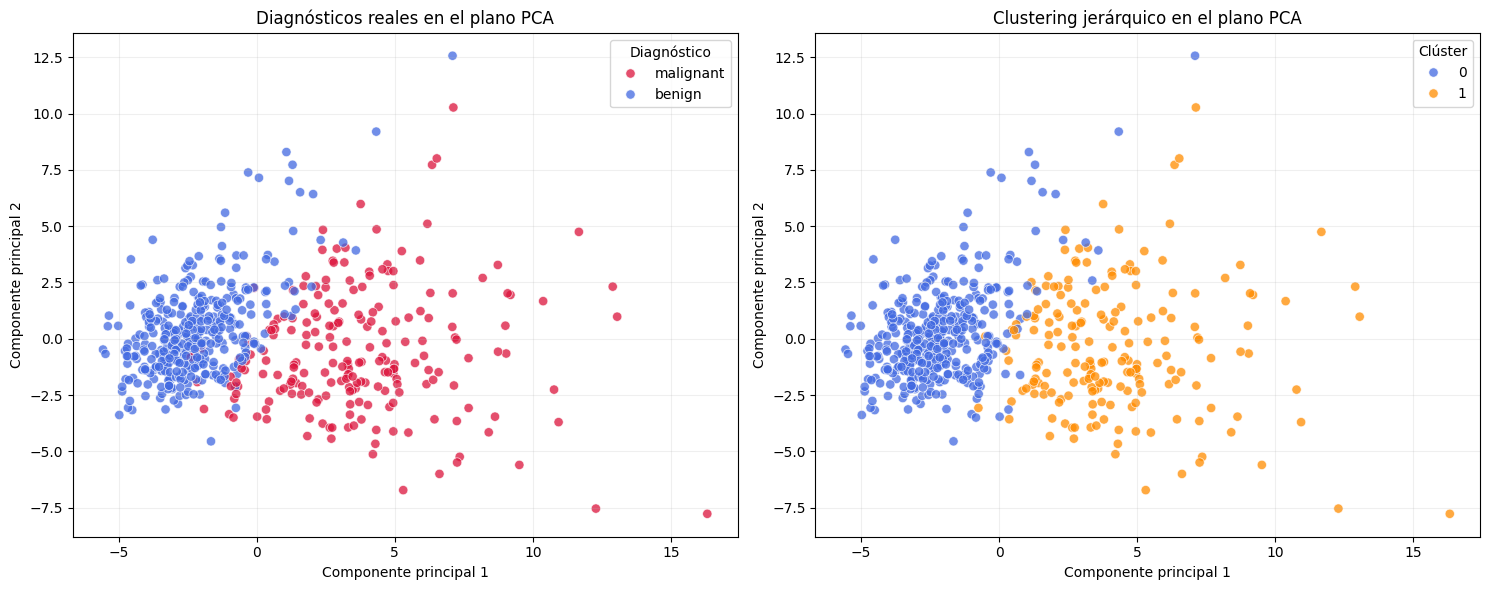

Varianza explicada por PC1: 44.27%
Varianza explicada por PC2: 18.97%
Varianza explicada acumulada: 63.24%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Clases reales
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=data.target_names[y],
    palette={
        "benign": "royalblue",
        "malignant": "crimson"
    },
    alpha=0.75,
    s=45,
    ax=axes[0]
)

axes[0].set_title("Diagnósticos reales en el plano PCA")
axes[0].set_xlabel("Componente principal 1")
axes[0].set_ylabel("Componente principal 2")
axes[0].legend(title="Diagnóstico")
axes[0].grid(alpha=0.2)

# Clústeres obtenidos
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=clusters_jerarquico,
    palette=["royalblue", "darkorange"],
    alpha=0.75,
    s=45,
    ax=axes[1]
)

axes[1].set_title("Clustering jerárquico en el plano PCA")
axes[1].set_xlabel("Componente principal 1")
axes[1].set_ylabel("Componente principal 2")
axes[1].legend(title="Clúster")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

varianza_pc1 = pca.explained_variance_ratio_[0] * 100
varianza_pc2 = pca.explained_variance_ratio_[1] * 100
varianza_acumulada = (varianza_pc1 + varianza_pc2)

print(f"Varianza explicada por PC1: {varianza_pc1:.2f}%")
print(f"Varianza explicada por PC2: {varianza_pc2:.2f}%")
print(f"Varianza explicada acumulada: {varianza_acumulada:.2f}%")

### Comparación visual con las etiquetas reales

Al comparar ambas gráficas se observa una correspondencia clara entre los agrupamientos y los diagnósticos reales. La región ocupada principalmente por las muestras benignas coincide con el clúster 0, mientras que la región donde se concentran las muestras malignas corresponde mayormente con el clúster 1.

Las principales diferencias aparecen en la zona central del plano PCA, donde las muestras benignas y malignas presentan traslape. Esto explica que el agrupamiento no coincida completamente con las etiquetas reales.

Los dos componentes principales conservan aproximadamente el 63.24% de la variabilidad total: PC1 explica cerca del 44.27% y PC2 alrededor del 18.97%. Por ello, la gráfica permite observar una parte importante de la estructura de los datos, pero no representa toda la información contenida en las 30 características.

En conclusión, el clustering jerárquico con enlace average, distancia cosine y 2 clústeres logró identificar una estructura natural considerablemente relacionada con los diagnósticos reales, sin utilizar dichas etiquetas durante el entrenamiento.

---

# Modelo 2: Clustering K-means

En esta sección se aplicará el algoritmo **K-means** al conjunto de datos de cáncer de mama.

El modelo se ajustará utilizando las **30 características estandarizadas**. Se probarán diferentes números de clústeres y se calculará el **coeficiente de silueta** para seleccionar la configuración final.

Las etiquetas reales de diagnóstico no se utilizarán durante el entrenamiento; solamente se emplearán posteriormente para comparar y evaluar los agrupamientos obtenidos.

---

In [ ]:
from sklearn.cluster import KMeans

resultados_kmeans = []

for n_clusters in range(2, 7):

    modelo_kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=20
    )

    etiquetas_kmeans = modelo_kmeans.fit_predict(X_scaled)

    silueta = silhouette_score(
        X_scaled,
        etiquetas_kmeans
    )

    valores, cantidades = np.unique(
        etiquetas_kmeans,
        return_counts=True
    )

    resultados_kmeans.append({
        "n_clusters": n_clusters,
        "silueta": silueta,
        "inercia": modelo_kmeans.inertia_,
        "distribucion": cantidades.tolist()
    })

resultados_kmeans_df = pd.DataFrame(resultados_kmeans)

resultados_kmeans_df

,n_clusters,silueta,inercia,distribucion
0,2,0.344974,11595.461474,"[189, 380]"
1,3,0.314384,10061.797818,"[110, 359, 100]"
2,4,0.280336,9257.362458,"[90, 346, 37, 96]"
3,5,0.158528,8557.727454,"[206, 158, 98, 71, 36]"
4,6,0.160367,7970.263835,"[89, 37, 154, 64, 205, 20]"


## Evaluación del número de clústeres

Para seleccionar el número de clústeres se comparan dos criterios:

- **Método del codo:** analiza la reducción de la inercia.
- **Coeficiente de silueta:** mide qué tan compactos y separados están los grupos. Un valor mayor representa una mejor agrupación.

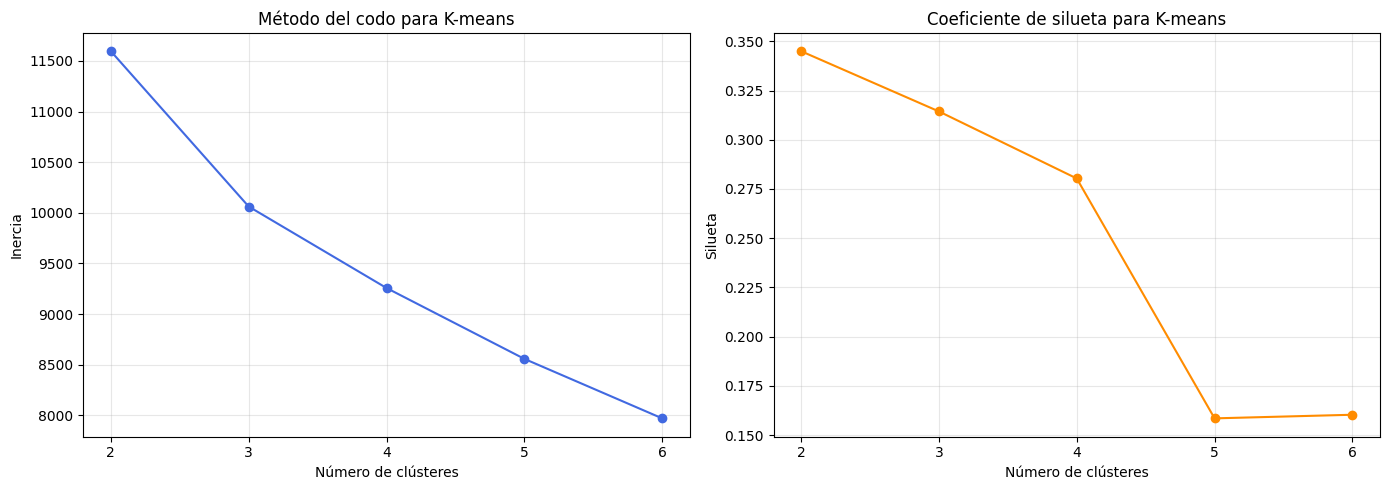

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Método del codo
axes[0].plot(
    resultados_kmeans_df["n_clusters"],
    resultados_kmeans_df["inercia"],
    marker="o",
    color="royalblue"
)

axes[0].set_title("Método del codo para K-means")
axes[0].set_xlabel("Número de clústeres")
axes[0].set_ylabel("Inercia")
axes[0].set_xticks(resultados_kmeans_df["n_clusters"])
axes[0].grid(alpha=0.3)

# Coeficiente de silueta
axes[1].plot(
    resultados_kmeans_df["n_clusters"],
    resultados_kmeans_df["silueta"],
    marker="o",
    color="darkorange"
)

axes[1].set_title("Coeficiente de silueta para K-means")
axes[1].set_xlabel("Número de clústeres")
axes[1].set_ylabel("Silueta")
axes[1].set_xticks(resultados_kmeans_df["n_clusters"])
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Selección de la configuración final

El método del codo muestra su reducción más pronunciada entre 2 y 3 clústeres, aunque no presenta un punto de quiebre completamente definido. Por otro lado, el coeficiente de silueta alcanza su valor máximo con **2 clústeres**, con un resultado de **0.344974**.

Esta configuración produjo grupos de **189 y 380 muestras**, por lo que no se observa el aislamiento de unas pocas observaciones extremas. Por estas razones, se seleccionó una configuración final de **K-means con 2 clústeres**.

La selección se realizó utilizando únicamente las características estandarizadas y las métricas internas del agrupamiento, sin utilizar los diagnósticos reales.

In [ ]:
mejor_modelo_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

clusters_kmeans = mejor_modelo_kmeans.fit_predict(X_scaled)

valores_kmeans, cantidades_kmeans = np.unique(
    clusters_kmeans,
    return_counts=True
)

silueta_kmeans = silhouette_score(
    X_scaled,
    clusters_kmeans
)

print("Clústeres:", valores_kmeans)
print("Cantidad de muestras por clúster:", cantidades_kmeans)
print("Coeficiente de silueta:", silueta_kmeans)
print("Inercia:", mejor_modelo_kmeans.inertia_)

Clústeres: [0 1]
Cantidad de muestras por clúster: [189 380]
Coeficiente de silueta: 0.3449740051034408
Inercia: 11595.461473962348


## Visualización de K-means con PCA

El modelo K-means fue ajustado utilizando las 30 características estandarizadas. Para representar gráficamente los resultados, las muestras y los centroides se proyectan en el plano PCA de dos dimensiones.

PCA se utiliza únicamente para la visualización y no para entrenar el modelo.

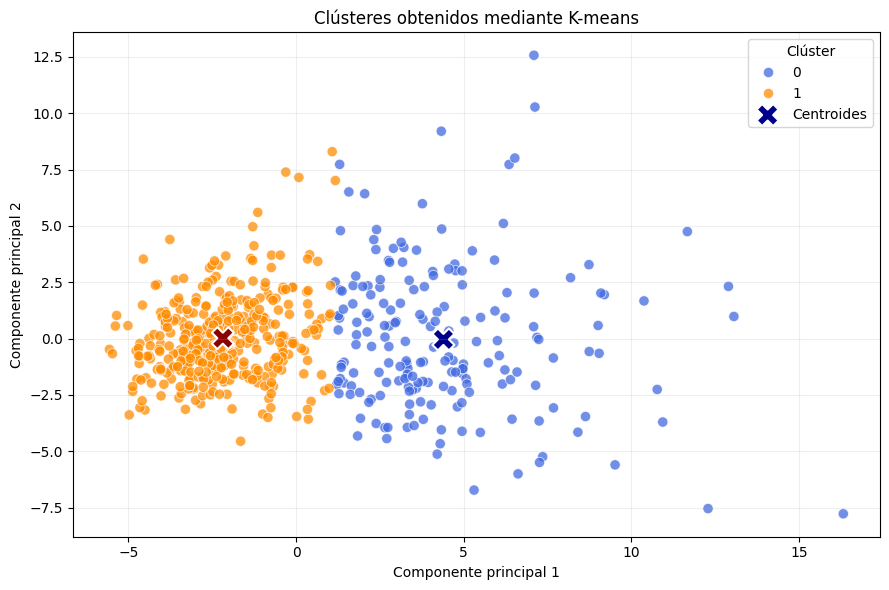

In [ ]:
# Proyección de los centroides al plano PCA
centroides_kmeans_pca = pca.transform(
    mejor_modelo_kmeans.cluster_centers_
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=clusters_kmeans,
    palette=["royalblue", "darkorange"],
    alpha=0.75,
    s=55
)

# Dibujar los centroides
plt.scatter(
    centroides_kmeans_pca[:, 0],
    centroides_kmeans_pca[:, 1],
    marker="X",
    s=250,
    c=["darkblue", "darkred"],
    edgecolor="white",
    linewidth=1.5,
    label="Centroides"
)

plt.title("Clústeres obtenidos mediante K-means")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Clúster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretación de la visualización

La proyección mediante PCA muestra que K-means identificó dos agrupamientos diferenciados principalmente a lo largo del primer componente principal. El clúster 1 se concentra mayormente en la región izquierda, mientras que el clúster 0 se distribuye principalmente hacia la región derecha.

Las marcas en forma de X representan la proyección de los centroides calculados por K-means. Existe cierto traslape entre ambos grupos en la zona central, lo que indica que algunas muestras poseen características similares.

El modelo fue ajustado utilizando las 30 características estandarizadas. PCA se utilizó únicamente para representar los resultados en dos dimensiones.

In [ ]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

diagnosticos_reales = pd.Series(
    target_names[y],
    name="Diagnóstico real"
)

clusters_kmeans_serie = pd.Series(
    clusters_kmeans,
    name="Clúster"
)

tabla_comparacion_kmeans = pd.crosstab(
    clusters_kmeans_serie,
    diagnosticos_reales
)

ari_kmeans = adjusted_rand_score(
    y,
    clusters_kmeans
)

nmi_kmeans = normalized_mutual_info_score(
    y,
    clusters_kmeans
)

print("Comparación entre clústeres y diagnósticos reales:")
display(tabla_comparacion_kmeans)

print("Índice Rand ajustado:", ari_kmeans)
print("Información mutua normalizada:", nmi_kmeans)

Comparación entre clústeres y diagnósticos reales:


Diagnóstico real,benign,malignant
Clúster,,
0,14,175
1,343,37


Índice Rand ajustado: 0.6707206476880808
Información mutua normalizada: 0.554612218410556


## Evaluación frente a las etiquetas reales

El clúster 0 agrupó 175 muestras malignas y 14 benignas, mientras que el clúster 1 agrupó 343 muestras benignas y 37 malignas. Por lo tanto, el clúster 0 presenta una fuerte correspondencia con los casos malignos y el clúster 1 con los casos benignos.

El índice Rand ajustado fue de 0.6707 y la información mutua normalizada fue de 0.5546. Estos resultados indican una correspondencia considerable entre los grupos encontrados por K-means y los diagnósticos reales, aunque existen muestras que no coinciden con la clase predominante de su clúster.

Las etiquetas reales se utilizaron únicamente para esta evaluación posterior y no para entrenar el modelo.

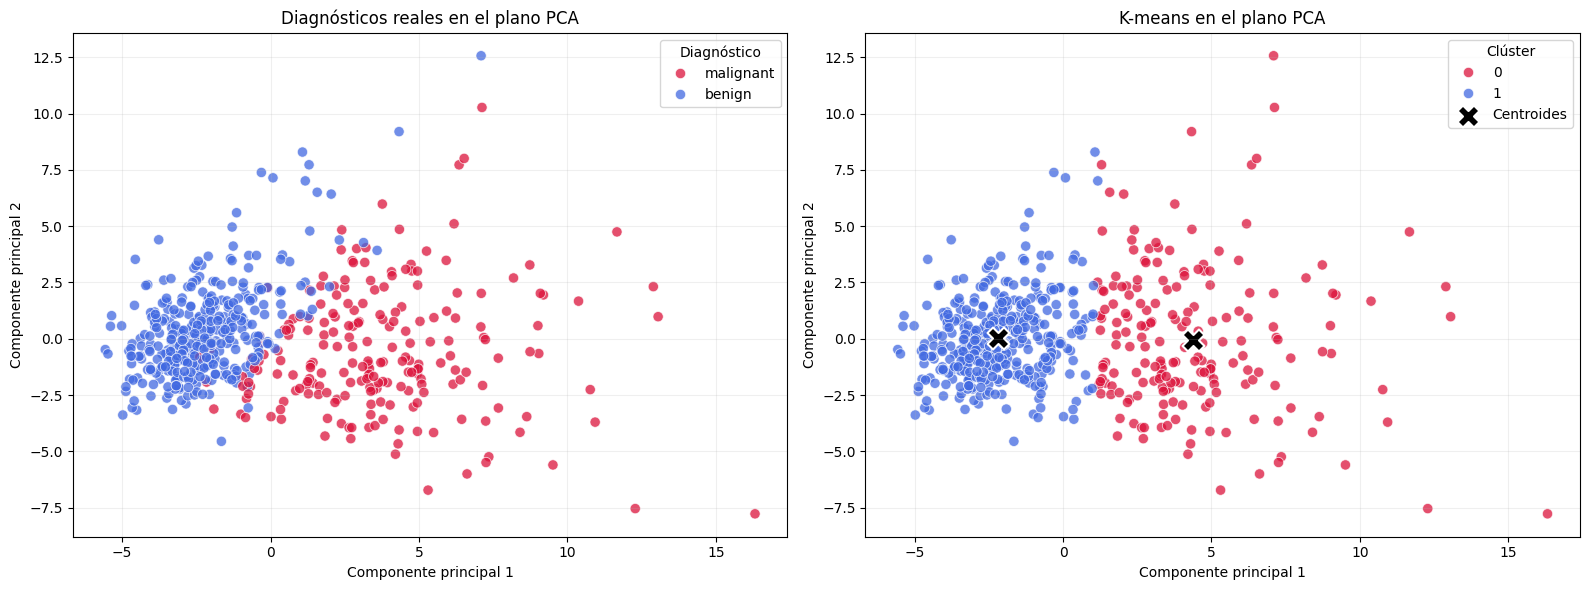

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Diagnósticos reales
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=diagnosticos_reales,
    palette={
        "malignant": "crimson",
        "benign": "royalblue"
    },
    alpha=0.75,
    s=55,
    ax=axes[0]
)

axes[0].set_title("Diagnósticos reales en el plano PCA")
axes[0].set_xlabel("Componente principal 1")
axes[0].set_ylabel("Componente principal 2")
axes[0].legend(title="Diagnóstico")
axes[0].grid(alpha=0.2)

# Clústeres obtenidos con K-means
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=clusters_kmeans,
    palette={
        0: "crimson",
        1: "royalblue"
    },
    alpha=0.75,
    s=55,
    ax=axes[1]
)

axes[1].scatter(
    centroides_kmeans_pca[:, 0],
    centroides_kmeans_pca[:, 1],
    marker="X",
    s=250,
    color="black",
    edgecolor="white",
    linewidth=1.5,
    label="Centroides"
)

axes[1].set_title("K-means en el plano PCA")
axes[1].set_xlabel("Componente principal 1")
axes[1].set_ylabel("Componente principal 2")
axes[1].legend(title="Clúster")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Comparación visual con las etiquetas reales

Al comparar ambas gráficas se observa una correspondencia clara entre los grupos obtenidos mediante K-means y los diagnósticos reales. El clúster 0 coincide principalmente con la región ocupada por las muestras malignas, mientras que el clúster 1 corresponde mayormente con las muestras benignas.

Las principales diferencias aparecen en la zona central del plano PCA, donde ambos diagnósticos presentan características similares. Esto explica que 14 muestras benignas quedaran en el clúster 0 y 37 muestras malignas en el clúster 1.

Los dos componentes principales conservan aproximadamente el 63.24 % de la variabilidad total: PC1 explica cerca del 44.27 % y PC2 alrededor del 18.97 %. Por ello, esta gráfica permite visualizar una parte importante de la estructura, pero no toda la información contenida en las 30 características.

En conclusión, K-means con 2 clústeres identificó una estructura considerablemente relacionada con los diagnósticos reales. Las etiquetas reales no se utilizaron para entrenar el modelo, sino únicamente para evaluar y contrastar los resultados obtenidos.

---

# Modelos supervisados

A continuación, se entrenarán y evaluarán modelos de clasificación utilizando las etiquetas reales del conjunto de cáncer de mama.

La evaluación principal se realizará con las 30 características originales mediante validación cruzada estratificada de 10 particiones. Las mismas particiones se utilizarán para todos los algoritmos.

---

## Modelo 3: K-Nearest Neighbors (k-NN)

Se probarán diferentes números de vecinos, métricas de distancia y esquemas de ponderación. La configuración final se seleccionará utilizando el F1-score macro promedio.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Estas serán las mismas particiones externas
# para todos los modelos supervisados
cv_externa = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Validación interna para buscar hiperparámetros
cv_interna = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Validación externa: 10 particiones estratificadas")
print("Validación interna: 5 particiones para buscar hiperparámetros")

Validación externa: 10 particiones estratificadas
Validación interna: 5 particiones para buscar hiperparámetros


In [ ]:
# Pipeline: el escalado se ajustará dentro de cada partición
pipeline_knn = Pipeline([
    ("escalado", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Configuraciones que se probarán
parametros_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["minkowski"],
    "knn__p": [1, 2, 3]
}

numero_configuraciones = (
    len(parametros_knn["knn__n_neighbors"])
    * len(parametros_knn["knn__weights"])
    * len(parametros_knn["knn__p"])
)

print("Número de configuraciones:", numero_configuraciones)
print("Vecinos:", parametros_knn["knn__n_neighbors"])
print("Ponderaciones:", parametros_knn["knn__weights"])
print("Valores de p:", parametros_knn["knn__p"])

Número de configuraciones: 36
Vecinos: [3, 5, 7, 9, 11, 15]
Ponderaciones: ['uniform', 'distance']
Valores de p: [1, 2, 3]


In [ ]:
# Verificar que seguimos utilizando el conjunto de cáncer de mama
print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

if X.shape != (569, 30):
    raise ValueError(
        "X ya no contiene los datos de cáncer de mama. "
        "Vuelve a ejecutar la celda donde se carga load_breast_cancer()."
    )

# Espacios para guardar las predicciones fuera de muestra
predicciones_knn = np.empty_like(y)

# Resultados obtenidos en cada partición externa
resultados_folds_knn = []
mejores_parametros_folds = []

for numero_fold, (indices_train, indices_test) in enumerate(
    cv_externa.split(X, y),
    start=1
):
    X_train = X[indices_train]
    X_test = X[indices_test]
    y_train = y[indices_train]
    y_test = y[indices_test]

    # Búsqueda de hiperparámetros usando únicamente el entrenamiento
    busqueda_knn = GridSearchCV(
        estimator=pipeline_knn,
        param_grid=parametros_knn,
        scoring="f1_macro",
        cv=cv_interna,
        n_jobs=-1
    )

    busqueda_knn.fit(X_train, y_train)

    # Predicciones de las muestras reservadas del fold externo
    y_pred = busqueda_knn.predict(X_test)
    predicciones_knn[indices_test] = y_pred

    resultados_folds_knn.append({
        "fold": numero_fold,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_macro": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "recall_macro": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "mae": mean_absolute_error(y_test, y_pred)
    })

    mejores_parametros_folds.append({
        "fold": numero_fold,
        "mejor_f1_interno": busqueda_knn.best_score_,
        **busqueda_knn.best_params_
    })

    print(
        f"Fold {numero_fold}/10 terminado — "
        f"mejor configuración: {busqueda_knn.best_params_}"
    )

# Convertir los resultados en tablas
resultados_folds_knn_df = pd.DataFrame(resultados_folds_knn)
mejores_parametros_folds_df = pd.DataFrame(
    mejores_parametros_folds
)

Forma de X: (569, 30)
Forma de y: (569,)
Fold 1/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 11, 'knn__p': 3, 'knn__weights': 'distance'}
Fold 2/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'uniform'}
Fold 3/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uniform'}
Fold 4/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uniform'}
Fold 5/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uniform'}
Fold 6/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'uniform'}
Fold 7/10 terminado — mejor configuración: {'knn__metric': 'minkowski', 'knn__n_neighbors': 9, 'knn__p': 2, 'knn__weights': 'distance'}
Fold 8/10 t

In [ ]:
# Mostrar las métricas obtenidas en cada fold
display(
    resultados_folds_knn_df.round(4)
)

# Calcular promedio y desviación estándar
columnas_metricas = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "mae"
]

resumen_knn = (
    resultados_folds_knn_df[columnas_metricas]
    .agg(["mean", "std"])
    .T
    .reset_index()
)

resumen_knn.columns = [
    "metrica",
    "promedio",
    "desviacion_estandar"
]

print("Resumen de k-NN con validación cruzada anidada:")
display(
    resumen_knn.round(4)
)

,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,0.9825,0.9861,0.9773,0.9813,0.0175
1,2,0.9825,0.9861,0.9773,0.9813,0.0175
2,3,0.9825,0.9865,0.9762,0.9810,0.0175
3,4,0.9298,0.9342,0.9147,0.9230,0.0702
4,5,0.9474,0.9480,0.9385,0.9429,0.0526
5,6,0.9474,0.9615,0.9286,0.9415,0.0526
6,7,1.0000,1.0000,1.0000,1.0000,0.0000
7,8,0.9474,0.9375,0.9583,0.9449,0.0526
8,9,0.9649,0.9737,0.9524,0.9615,0.0351
9,10,0.9643,0.9730,0.9524,0.9611,0.0357


Resumen de k-NN con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9648,0.0219
1,precision_macro,0.9687,0.0226
2,recall_macro,0.9576,0.0259
3,f1_macro,0.9619,0.0239
4,mae,0.0352,0.0219


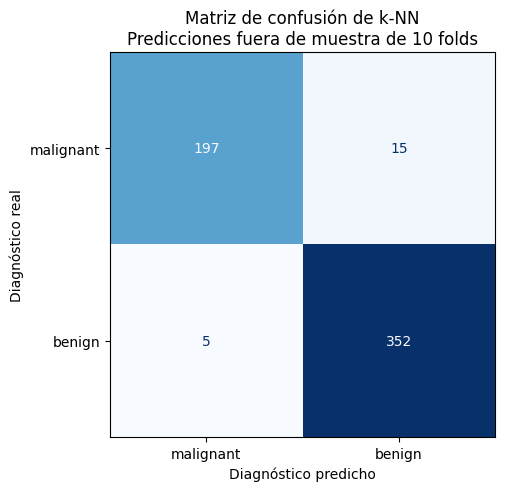

Matriz de confusión:
[[197  15]
 [  5 352]]
Predicciones correctas: 549
Predicciones incorrectas: 20


In [ ]:
# Matriz de confusión con las predicciones fuera de muestra
matriz_confusion_knn = confusion_matrix(
    y,
    predicciones_knn
)

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion_knn,
    display_labels=target_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title(
    "Matriz de confusión de k-NN\n"
    "Predicciones fuera de muestra de 10 folds"
)
plt.xlabel("Diagnóstico predicho")
plt.ylabel("Diagnóstico real")
plt.show()

print("Matriz de confusión:")
print(matriz_confusion_knn)

print(
    "Predicciones correctas:",
    np.trace(matriz_confusion_knn)
)

print(
    "Predicciones incorrectas:",
    np.sum(matriz_confusion_knn)
    - np.trace(matriz_confusion_knn)
)

In [ ]:
# Búsqueda de la configuración final utilizando todos los datos
busqueda_final_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=parametros_knn,
    scoring="f1_macro",
    cv=cv_externa,
    n_jobs=-1,
    refit=True
)

busqueda_final_knn.fit(X, y)

# Modelo final ya ajustado con las 569 muestras
mejor_modelo_knn = busqueda_final_knn.best_estimator_

print("Mejores parámetros finales:")
print(busqueda_final_knn.best_params_)

print(
    "F1 macro promedio durante la búsqueda:",
    round(busqueda_final_knn.best_score_, 4)
)

# Tabla de las diez mejores configuraciones
resultados_busqueda_knn = pd.DataFrame(
    busqueda_final_knn.cv_results_
)

columnas_busqueda = [
    "param_knn__n_neighbors",
    "param_knn__weights",
    "param_knn__p",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

top_configuraciones_knn = (
    resultados_busqueda_knn[columnas_busqueda]
    .sort_values("rank_test_score")
    .head(10)
    .reset_index(drop=True)
)

display(
    top_configuraciones_knn.round(4)
)

Mejores parámetros finales:
{'knn__metric': 'minkowski', 'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uniform'}
F1 macro promedio durante la búsqueda: 0.9732


,param_knn__n_neighbors,param_knn__weights,param_knn__p,mean_test_score,std_test_score,rank_test_score
0,3,uniform,1,0.9732,0.0246,1
1,3,distance,1,0.9732,0.0246,1
2,5,distance,2,0.9674,0.0196,3
3,5,uniform,2,0.9674,0.0196,3
4,3,uniform,2,0.9654,0.0192,5
5,3,distance,2,0.9654,0.0192,5
6,5,distance,3,0.9636,0.0139,7
7,5,uniform,3,0.9636,0.0139,7
8,3,distance,3,0.9635,0.0222,9
9,3,uniform,3,0.9635,0.0222,9


### Selección de la configuración final de k-NN

Se evaluaron 36 configuraciones mediante distintas combinaciones del número de vecinos, el esquema de ponderación y la distancia de Minkowski. La selección se realizó utilizando el F1-score macro promedio.

La configuración seleccionada utiliza **3 vecinos**, ponderación **uniforme** y distancia de Minkowski con **p = 1**, equivalente a la distancia Manhattan. Esta configuración obtuvo un F1 macro promedio de **0.9732** durante la búsqueda de hiperparámetros.

Las ponderaciones uniforme y por distancia obtuvieron el mismo resultado. Se conservó la ponderación uniforme por ser la configuración seleccionada automáticamente por la búsqueda y por ofrecer una interpretación más sencilla.

La evaluación principal e imparcial se obtuvo mediante validación cruzada anidada con las 30 características originales. Sus resultados fueron: accuracy de **0.9648**, precision macro de **0.9687**, recall macro de **0.9576**, F1 macro de **0.9619** y MAE de **0.0352**.

Forma de X_pca: (569, 2)


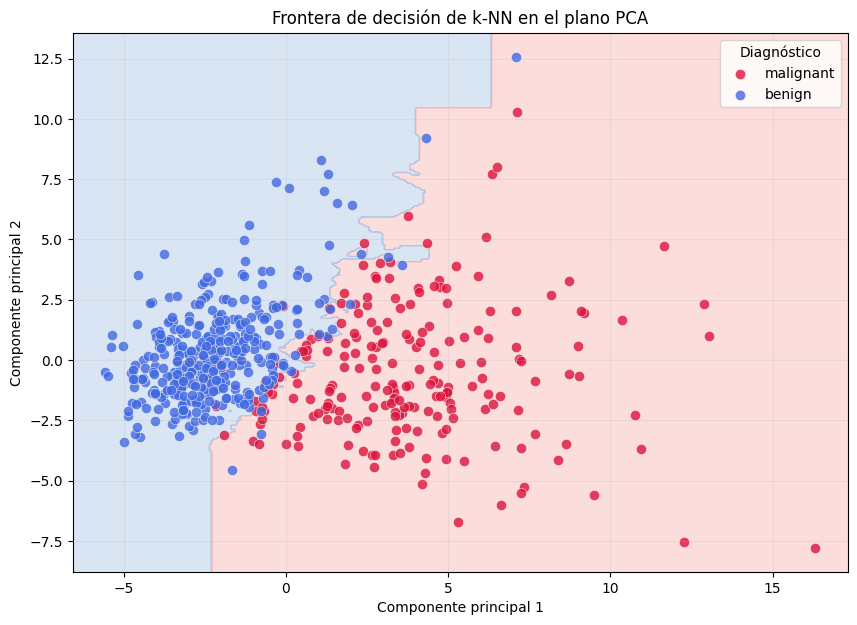

In [ ]:
from matplotlib.colors import ListedColormap

# Comprobar que X_pca contiene las dos componentes
print("Forma de X_pca:", X_pca.shape)

# Recuperar los hiperparámetros seleccionados
parametros_finales_knn = busqueda_final_knn.best_params_

# Modelo adicional entrenado exclusivamente en el plano PCA
modelo_knn_pca = Pipeline([
    ("escalado", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=parametros_finales_knn[
            "knn__n_neighbors"
        ],
        weights=parametros_finales_knn[
            "knn__weights"
        ],
        metric=parametros_finales_knn[
            "knn__metric"
        ],
        p=parametros_finales_knn[
            "knn__p"
        ]
    ))
])

modelo_knn_pca.fit(X_pca, y)

# Crear la malla del plano PCA
pc1_min = X_pca[:, 0].min() - 1
pc1_max = X_pca[:, 0].max() + 1
pc2_min = X_pca[:, 1].min() - 1
pc2_max = X_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(pc1_min, pc1_max, 400),
    np.linspace(pc2_min, pc2_max, 400)
)

puntos_malla = np.c_[xx.ravel(), yy.ravel()]
predicciones_malla = modelo_knn_pca.predict(
    puntos_malla
)
predicciones_malla = predicciones_malla.reshape(
    xx.shape
)

# Colores: 0 = malignant, 1 = benign
colores_fondo = ListedColormap([
    "#f7b6b2",
    "#aec7e8"
])

plt.figure(figsize=(10, 7))

plt.contourf(
    xx,
    yy,
    predicciones_malla,
    alpha=0.45,
    cmap=colores_fondo
)

# Dibujar las muestras reales
for clase, nombre, color in zip(
    [0, 1],
    target_names,
    ["crimson", "royalblue"]
):
    mascara = y == clase

    plt.scatter(
        X_pca[mascara, 0],
        X_pca[mascara, 1],
        color=color,
        label=nombre,
        edgecolor="white",
        linewidth=0.4,
        alpha=0.8,
        s=55
    )

plt.title(
    "Frontera de decisión de k-NN en el plano PCA"
)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Diagnóstico")
plt.grid(alpha=0.2)
plt.show()

### Frontera de decisión de k-NN en el plano PCA

La frontera de decisión muestra que k-NN identifica una separación clara entre gran parte de las muestras benignas y malignas. La región izquierda del plano se clasifica principalmente como benigna, mientras que la región derecha se clasifica mayormente como maligna.

La forma irregular de la frontera es característica de k-NN, ya que el algoritmo toma decisiones locales basadas en los tres vecinos más cercanos. En la región central existe un traslape entre ambas clases, lo que produce cambios en la frontera y algunas clasificaciones incorrectas.

Los dos componentes principales conservan aproximadamente el 63.24 % de la variabilidad total: PC1 explica cerca del 44.27 % y PC2 alrededor del 18.97 %. Por ello, la gráfica permite observar una parte importante de la estructura, pero no contiene toda la información de las 30 características originales.

Esta frontera corresponde a una versión adicional de k-NN entrenada específicamente con PC1 y PC2 para fines de visualización. No representa una proyección exacta de la frontera del modelo principal de 30 dimensiones. Las métricas oficiales se obtuvieron utilizando las 30 características originales mediante validación cruzada anidada.

---

## Modelo 4: Naive Bayes

Se utilizará la variante **Gaussian Naive Bayes**, debido a que las 30 características del conjunto de cáncer de mama son variables numéricas continuas.

Se probarán distintos valores del parámetro `var_smoothing` y la configuración final se seleccionará utilizando el F1-score macro. La evaluación principal se realizará con las 30 características originales mediante validación cruzada estratificada anidada, utilizando las mismas 10 particiones externas empleadas en k-NN.

También se entrenará una versión adicional con las dos componentes principales para visualizar su frontera de decisión en el plano PCA.

---

In [ ]:
from sklearn.naive_bayes import GaussianNB

# Pipeline para que el escalado se ajuste
# únicamente con los datos de entrenamiento de cada fold
pipeline_nb = Pipeline([
    ("escalado", StandardScaler()),
    ("nb", GaussianNB())
])

# Rango amplio desde 10^-12 hasta 10^0
# para que var_smoothing produzca cambios reales
valores_var_smoothing = np.logspace(
    -12,
    0,
    13
)

parametros_nb = {
    "nb__var_smoothing": valores_var_smoothing
}

print(
    "Número de configuraciones:",
    len(valores_var_smoothing)
)

print("Valores de var_smoothing:")

for valor in valores_var_smoothing:
    print(f"{valor:.0e}")

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

# Comprobar que X y y siguen siendo
# los datos de cáncer de mama
if X.shape != (569, 30):
    raise ValueError(
        "X ya no contiene la base de cáncer de mama. "
        "Vuelve a ejecutar la carga de load_breast_cancer() "
        "y no ejecutes la generación de datos sintéticos "
        "del código del profesor."
    )

if y.shape != (569,):
    raise ValueError(
        "y ya no contiene las 569 etiquetas "
        "del conjunto de cáncer de mama."
    )

Número de configuraciones: 13
Valores de var_smoothing:
1e-12
1e-11
1e-10
1e-09
1e-08
1e-07
1e-06
1e-05
1e-04
1e-03
1e-02
1e-01
1e+00
Forma de X: (569, 30)
Forma de y: (569,)


In [ ]:
# Predicciones fuera de muestra
predicciones_nb = np.empty_like(y)

# Resultados de cada fold externo
resultados_folds_nb = []
mejores_parametros_nb_folds = []

for numero_fold, (indices_train, indices_test) in enumerate(
    cv_externa.split(X, y),
    start=1
):
    X_train = X[indices_train]
    X_test = X[indices_test]
    y_train = y[indices_train]
    y_test = y[indices_test]

    # Búsqueda interna del mejor var_smoothing
    busqueda_nb = GridSearchCV(
        estimator=pipeline_nb,
        param_grid=parametros_nb,
        scoring="f1_macro",
        cv=cv_interna,
        n_jobs=-1
    )

    busqueda_nb.fit(X_train, y_train)

    # Predicción del fold externo
    y_pred = busqueda_nb.predict(X_test)
    predicciones_nb[indices_test] = y_pred

    resultados_folds_nb.append({
        "fold": numero_fold,
        "accuracy": accuracy_score(
            y_test,
            y_pred
        ),
        "precision_macro": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "recall_macro": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "mae": mean_absolute_error(
            y_test,
            y_pred
        )
    })

    mejores_parametros_nb_folds.append({
        "fold": numero_fold,
        "mejor_f1_interno": busqueda_nb.best_score_,
        "var_smoothing":
            busqueda_nb.best_params_[
                "nb__var_smoothing"
            ]
    })

    print(
        f"Fold {numero_fold}/10 terminado — "
        f"mejor var_smoothing: "
        f"{busqueda_nb.best_params_['nb__var_smoothing']:.2e}"
    )

# Convertir resultados en tablas
resultados_folds_nb_df = pd.DataFrame(
    resultados_folds_nb
)

mejores_parametros_nb_folds_df = pd.DataFrame(
    mejores_parametros_nb_folds
)

Fold 1/10 terminado — mejor var_smoothing: 1.00e-01
Fold 2/10 terminado — mejor var_smoothing: 1.00e-01
Fold 3/10 terminado — mejor var_smoothing: 1.00e-12
Fold 4/10 terminado — mejor var_smoothing: 1.00e-01
Fold 5/10 terminado — mejor var_smoothing: 1.00e-12
Fold 6/10 terminado — mejor var_smoothing: 1.00e-01
Fold 7/10 terminado — mejor var_smoothing: 1.00e-01
Fold 8/10 terminado — mejor var_smoothing: 1.00e-02
Fold 9/10 terminado — mejor var_smoothing: 1.00e-12
Fold 10/10 terminado — mejor var_smoothing: 1.00e-01


In [ ]:
# Mostrar métricas obtenidas en cada fold
display(
    resultados_folds_nb_df.round(4)
)

# Calcular promedio y desviación estándar
columnas_metricas_nb = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "mae"
]

resumen_nb = (
    resultados_folds_nb_df[columnas_metricas_nb]
    .agg(["mean", "std"])
    .T
    .reset_index()
)

resumen_nb.columns = [
    "metrica",
    "promedio",
    "desviacion_estandar"
]

print(
    "Resumen de Gaussian Naive Bayes "
    "con validación cruzada anidada:"
)

display(
    resumen_nb.round(4)
)

,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,0.9649,0.9730,0.9545,0.9623,0.0351
1,2,0.9474,0.9418,0.9487,0.9449,0.0526
2,3,0.9298,0.9246,0.9246,0.9246,0.0702
3,4,0.9123,0.9390,0.8810,0.9000,0.0877
4,5,0.9474,0.9480,0.9385,0.9429,0.0526
5,6,0.9123,0.9390,0.8810,0.9000,0.0877
6,7,0.9123,0.9095,0.9008,0.9048,0.0877
7,8,0.8947,0.8889,0.9167,0.8920,0.1053
8,9,0.9123,0.9095,0.9008,0.9048,0.0877
9,10,0.9643,0.9730,0.9524,0.9611,0.0357


Resumen de Gaussian Naive Bayes con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9298,0.0247
1,precision_macro,0.9346,0.0272
2,recall_macro,0.9199,0.0283
3,f1_macro,0.9237,0.0270
4,mae,0.0702,0.0247


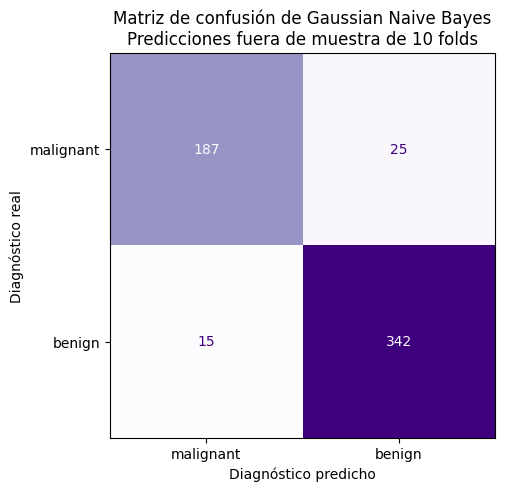

Matriz de confusión:
[[187  25]
 [ 15 342]]
Predicciones correctas: 529
Predicciones incorrectas: 40


In [ ]:
# Matriz de confusión con predicciones fuera de muestra
matriz_confusion_nb = confusion_matrix(
    y,
    predicciones_nb
)

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion_nb,
    display_labels=target_names
)

disp.plot(
    cmap="Purples",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title(
    "Matriz de confusión de Gaussian Naive Bayes\n"
    "Predicciones fuera de muestra de 10 folds"
)
plt.xlabel("Diagnóstico predicho")
plt.ylabel("Diagnóstico real")
plt.show()

print("Matriz de confusión:")
print(matriz_confusion_nb)

print(
    "Predicciones correctas:",
    np.trace(matriz_confusion_nb)
)

print(
    "Predicciones incorrectas:",
    np.sum(matriz_confusion_nb)
    - np.trace(matriz_confusion_nb)
)

In [ ]:
# Búsqueda de la configuración final de Naive Bayes
busqueda_final_nb = GridSearchCV(
    estimator=pipeline_nb,
    param_grid=parametros_nb,
    scoring="f1_macro",
    cv=cv_externa,
    n_jobs=-1,
    refit=True
)

busqueda_final_nb.fit(X, y)

# Modelo final ajustado con todas las muestras
mejor_modelo_nb = busqueda_final_nb.best_estimator_

print("Mejor parámetro final:")
print(busqueda_final_nb.best_params_)

print(
    "F1 macro promedio durante la búsqueda:",
    round(busqueda_final_nb.best_score_, 4)
)

# Tabla con las configuraciones evaluadas
resultados_busqueda_nb = pd.DataFrame(
    busqueda_final_nb.cv_results_
)

columnas_busqueda_nb = [
    "param_nb__var_smoothing",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

top_configuraciones_nb = (
    resultados_busqueda_nb[columnas_busqueda_nb]
    .sort_values("rank_test_score")
    .head(10)
    .reset_index(drop=True)
)

display(
    top_configuraciones_nb.round(6)
)

Mejor parámetro final:
{'nb__var_smoothing': np.float64(0.1)}
F1 macro promedio durante la búsqueda: 0.9289


,param_nb__var_smoothing,mean_test_score,std_test_score,rank_test_score
0,0.100000,0.928946,0.022189,1
1,0.000000,0.925951,0.033666,2
2,0.000000,0.925951,0.033666,2
3,0.000000,0.925951,0.033666,2
4,0.000000,0.925951,0.033666,2
5,0.000000,0.925951,0.033666,2
6,0.000001,0.925951,0.033666,2
7,0.000000,0.925951,0.033666,2
8,0.000010,0.925951,0.033666,2
9,0.000100,0.925951,0.033666,2


### Selección de la configuración final de Gaussian Naive Bayes

Se probaron 13 valores de `var_smoothing`, comprendidos entre \(10^{-12}\) y \(10^{0}\). Este parámetro agrega una pequeña corrección a las varianzas calculadas por Gaussian Naive Bayes para mejorar su estabilidad numérica.

La configuración seleccionada utiliza un `var_smoothing` de **0.1**, ya que obtuvo el mayor F1-score macro promedio, con un valor de **0.9289** durante la búsqueda de hiperparámetros. También presentó una desviación estándar menor que las configuraciones con valores de suavización más pequeños.

La evaluación principal se realizó mediante validación cruzada estratificada anidada utilizando las 30 características originales. El escalado y la selección del hiperparámetro se ajustaron únicamente con los datos de entrenamiento de cada partición para evitar fugas de información.

Gaussian Naive Bayes obtuvo un desempeño inferior al de k-NN. Una posible explicación es que Naive Bayes supone independencia condicional entre las características, mientras que varias variables del conjunto de cáncer de mama, como radio, perímetro y área, presentan relaciones entre sí.

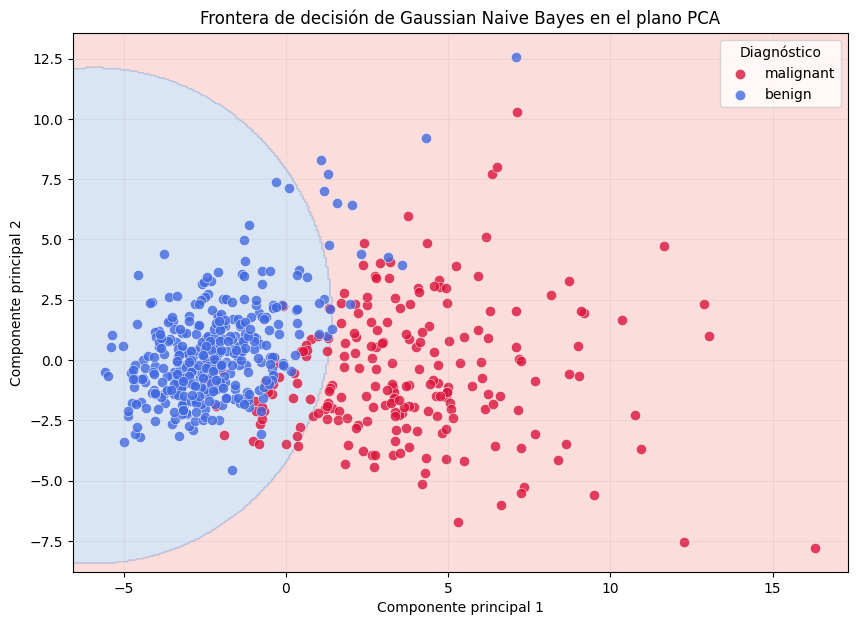

In [ ]:
from matplotlib.colors import ListedColormap

# Parámetro seleccionado
var_smoothing_final = (
    busqueda_final_nb.best_params_[
        "nb__var_smoothing"
    ]
)

# Modelo adicional entrenado únicamente con PC1 y PC2
modelo_nb_pca = Pipeline([
    ("escalado", StandardScaler()),
    ("nb", GaussianNB(
        var_smoothing=var_smoothing_final
    ))
])

modelo_nb_pca.fit(X_pca, y)

# Crear malla del plano PCA
pc1_min = X_pca[:, 0].min() - 1
pc1_max = X_pca[:, 0].max() + 1
pc2_min = X_pca[:, 1].min() - 1
pc2_max = X_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(pc1_min, pc1_max, 400),
    np.linspace(pc2_min, pc2_max, 400)
)

puntos_malla = np.c_[
    xx.ravel(),
    yy.ravel()
]

predicciones_malla_nb = modelo_nb_pca.predict(
    puntos_malla
).reshape(xx.shape)

colores_fondo = ListedColormap([
    "#f7b6b2",
    "#aec7e8"
])

plt.figure(figsize=(10, 7))

plt.contourf(
    xx,
    yy,
    predicciones_malla_nb,
    alpha=0.45,
    cmap=colores_fondo
)

for clase, nombre, color in zip(
    [0, 1],
    target_names,
    ["crimson", "royalblue"]
):
    mascara = y == clase

    plt.scatter(
        X_pca[mascara, 0],
        X_pca[mascara, 1],
        color=color,
        label=nombre,
        edgecolor="white",
        linewidth=0.4,
        alpha=0.8,
        s=55
    )

plt.title(
    "Frontera de decisión de Gaussian Naive Bayes "
    "en el plano PCA"
)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Diagnóstico")
plt.grid(alpha=0.2)
plt.show()

### Interpretación de la frontera de decisión

La gráfica muestra la frontera de decisión de Gaussian Naive Bayes utilizando las dos primeras componentes principales. La región azul corresponde a las predicciones de la clase **benign** y la región rosa a las predicciones de la clase **malignant**.

El modelo genera una frontera curva porque estima una distribución gaussiana para cada característica y cada clase. Se observa una separación general entre los diagnósticos: la mayoría de las muestras benignas se concentra en la región izquierda, mientras que gran parte de las muestras malignas se encuentra en la región derecha. Sin embargo, existe una zona de superposición cerca de la frontera, donde se producen algunas clasificaciones incorrectas.

Las dos componentes representadas explican aproximadamente el **63.24 % de la varianza total** (44.27 % la primera y 18.97 % la segunda). Por ello, esta gráfica solamente permite interpretar visualmente el comportamiento del clasificador en dos dimensiones. El resultado oficial se obtuvo con las **30 características originales** y validación cruzada anidada.

Gaussian Naive Bayes obtuvo una exactitud promedio de **0.9298 ± 0.0247** y un F1 macro de **0.9237 ± 0.0270**. La matriz de confusión fuera de muestra fue:

- 187 muestras malignas clasificadas correctamente.
- 25 muestras malignas clasificadas como benignas.
- 15 muestras benignas clasificadas como malignas.
- 342 muestras benignas clasificadas correctamente.

El valor final seleccionado para `var_smoothing` fue **0.1**.

---

## Modelo 5: Support Vector Machine (SVM)

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid
)

# Verificar que seguimos utilizando la base de cáncer de mama
if X.shape != (569, 30):
    raise ValueError(
        "X ya no contiene la base de cáncer de mama. "
        "No ejecutes la generación de datos sintéticos "
        "del código del profesor."
    )

# Pipeline para evitar fugas de información
pipeline_svm = Pipeline([
    ("escalado", StandardScaler()),
    ("svm", SVC())
])

# Configuraciones que se probarán
parametros_svm = [
    # Kernel lineal: gamma no se utiliza
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },

    # Kernel radial
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.001, 0.01, 0.1, 1]
    },

    # Kernel polinomial
    {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.01, 0.1],
        "svm__degree": [2, 3]
    },

    # Kernel sigmoide
    {
        "svm__kernel": ["sigmoid"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.001, 0.01, 0.1, 1]
    }
]

# Mismas particiones utilizadas en los modelos anteriores
cv_externa = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_interna = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

numero_configuraciones = len(list(ParameterGrid(parametros_svm)))

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)
print("Número de configuraciones de SVM:", numero_configuraciones)
print("Validación externa: 10 particiones estratificadas")
print("Validación interna: 5 particiones para buscar hiperparámetros")

Forma de X: (569, 30)
Forma de y: (569,)
Número de configuraciones de SVM: 68
Validación externa: 10 particiones estratificadas
Validación interna: 5 particiones para buscar hiperparámetros


In [ ]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error
)

# Espacios para guardar resultados y predicciones fuera de muestra
resultados_svm = []
mejores_parametros_svm = []

predicciones_oof_svm = np.empty_like(y)
predicciones_oof_svm[:] = -1

# Validación cruzada externa de 10 folds
for numero_fold, (indices_train, indices_test) in enumerate(
    cv_externa.split(X, y),
    start=1
):
    X_train = X[indices_train]
    X_test = X[indices_test]
    y_train = y[indices_train]
    y_test = y[indices_test]

    # Búsqueda de hiperparámetros únicamente con los datos de entrenamiento
    busqueda_svm = GridSearchCV(
        estimator=pipeline_svm,
        param_grid=parametros_svm,
        scoring="f1_macro",
        cv=cv_interna,
        n_jobs=-1,
        refit=True
    )

    busqueda_svm.fit(X_train, y_train)

    # Predicción sobre el fold externo no utilizado durante el ajuste
    y_pred = busqueda_svm.predict(X_test)

    # Guardar predicciones en sus posiciones originales
    predicciones_oof_svm[indices_test] = y_pred

    # Calcular métricas del fold
    resultados_svm.append({
        "fold": numero_fold,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_macro": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "recall_macro": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "mae": mean_absolute_error(y_test, y_pred)
    })

    mejores_parametros_svm.append(
        busqueda_svm.best_params_
    )

    print(
        f"Fold {numero_fold}/10 terminado — "
        f"mejor configuración: {busqueda_svm.best_params_}"
    )

# Convertir los resultados a tabla
resultados_svm_df = pd.DataFrame(resultados_svm)

# Resumen de promedios y desviaciones estándar
metricas_svm = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "mae"
]

resumen_svm_df = pd.DataFrame({
    "metrica": metricas_svm,
    "promedio": [
        resultados_svm_df[metrica].mean()
        for metrica in metricas_svm
    ],
    "desviacion_estandar": [
        resultados_svm_df[metrica].std(ddof=0)
        for metrica in metricas_svm
    ]
})

display(resultados_svm_df.round(4))

print(
    "\nResumen de SVM con "
    "validación cruzada anidada:"
)
display(resumen_svm_df.round(4))

Fold 1/10 terminado — mejor configuración: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Fold 2/10 terminado — mejor configuración: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Fold 3/10 terminado — mejor configuración: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Fold 4/10 terminado — mejor configuración: {'svm__C': 0.1, 'svm__kernel': 'linear'}
Fold 5/10 terminado — mejor configuración: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Fold 6/10 terminado — mejor configuración: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Fold 7/10 terminado — mejor configuración: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Fold 8/10 terminado — mejor configuración: {'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Fold 9/10 terminado — mejor configuración: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Fold 10/10 terminado — mejor configuración: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}


,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,1.0000,1.0000,1.0000,1.0000,0.0000
1,2,0.9825,0.9783,0.9857,0.9816,0.0175
2,3,0.9474,0.9403,0.9484,0.9440,0.0526
3,4,0.9474,0.9615,0.9286,0.9415,0.0526
4,5,0.9649,0.9623,0.9623,0.9623,0.0351
5,6,0.9649,0.9737,0.9524,0.9615,0.0351
6,7,1.0000,1.0000,1.0000,1.0000,0.0000
7,8,0.9825,0.9773,0.9861,0.9813,0.0175
8,9,0.9825,0.9865,0.9762,0.9810,0.0175
9,10,1.0000,1.0000,1.0000,1.0000,0.0000



Resumen de SVM con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9772,0.0193
1,precision_macro,0.9780,0.0187
2,recall_macro,0.9740,0.0237
3,f1_macro,0.9753,0.0210
4,mae,0.0228,0.0193


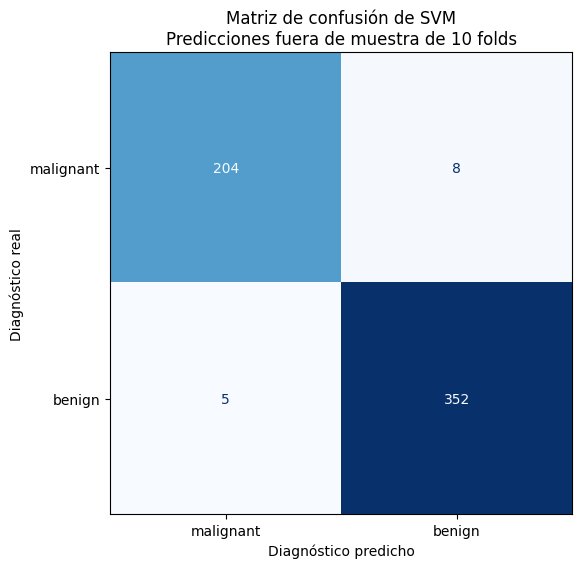

Matriz de confusión:
[[204   8]
 [  5 352]]
Predicciones correctas: 556
Predicciones incorrectas: 13
Malignos clasificados como benignos: 8
Benignos clasificados como malignos: 5


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Verificar que todas las muestras tengan una predicción fuera de muestra
if np.any(predicciones_oof_svm == -1):
    raise ValueError(
        "Existen muestras sin predicción fuera de muestra."
    )

# Matriz de confusión con las predicciones de los 10 folds externos
matriz_svm = confusion_matrix(
    y,
    predicciones_oof_svm,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_svm,
    display_labels=target_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title(
    "Matriz de confusión de SVM\n"
    "Predicciones fuera de muestra de 10 folds"
)
plt.xlabel("Diagnóstico predicho")
plt.ylabel("Diagnóstico real")
plt.show()

print("Matriz de confusión:")
print(matriz_svm)

print(
    "Predicciones correctas:",
    np.trace(matriz_svm)
)

print(
    "Predicciones incorrectas:",
    matriz_svm.sum() - np.trace(matriz_svm)
)

print(
    "Malignos clasificados como benignos:",
    matriz_svm[0, 1]
)

print(
    "Benignos clasificados como malignos:",
    matriz_svm[1, 0]
)

In [ ]:
# Búsqueda final utilizando toda la base de datos
busqueda_final_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=parametros_svm,
    scoring="f1_macro",
    cv=cv_externa,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)

busqueda_final_svm.fit(X, y)

# Modelo final ya ajustado con la mejor configuración
mejor_modelo_svm = busqueda_final_svm.best_estimator_

print("Mejores parámetros finales:")
print(busqueda_final_svm.best_params_)

print(
    "F1 macro promedio durante la búsqueda:",
    round(busqueda_final_svm.best_score_, 4)
)

# Tabla de resultados de la búsqueda
resultados_busqueda_svm = pd.DataFrame(
    busqueda_final_svm.cv_results_
)

columnas_svm = [
    "param_svm__kernel",
    "param_svm__C",
    "param_svm__gamma",
    "param_svm__degree",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_busqueda_svm = (
    resultados_busqueda_svm[columnas_svm]
    .sort_values(
        by=["rank_test_score", "mean_test_score"],
        ascending=[True, False]
    )
    .head(10)
    .reset_index(drop=True)
)

display(tabla_busqueda_svm.round(4))

Mejores parámetros finales:
{'svm__C': 10, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
F1 macro promedio durante la búsqueda: 0.9754


,param_svm__kernel,param_svm__C,param_svm__gamma,param_svm__degree,mean_test_score,std_test_score,rank_test_score
0,rbf,10.0,scale,NaN,0.9754,0.0192,1
1,rbf,10.0,0.01,NaN,0.9754,0.0210,2
2,rbf,1.0,scale,NaN,0.9736,0.0208,3
3,rbf,100.0,0.01,NaN,0.9735,0.0245,4
4,linear,0.1,NaN,NaN,0.9733,0.0180,5
5,sigmoid,100.0,0.001,NaN,0.9733,0.0180,5
6,rbf,100.0,0.001,NaN,0.9712,0.0251,7
7,linear,10.0,NaN,NaN,0.9699,0.0195,8
8,linear,1.0,NaN,NaN,0.9697,0.0272,9
9,rbf,10.0,0.001,NaN,0.9672,0.0270,10


Parámetros utilizados en el modelo SVM 2D: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}


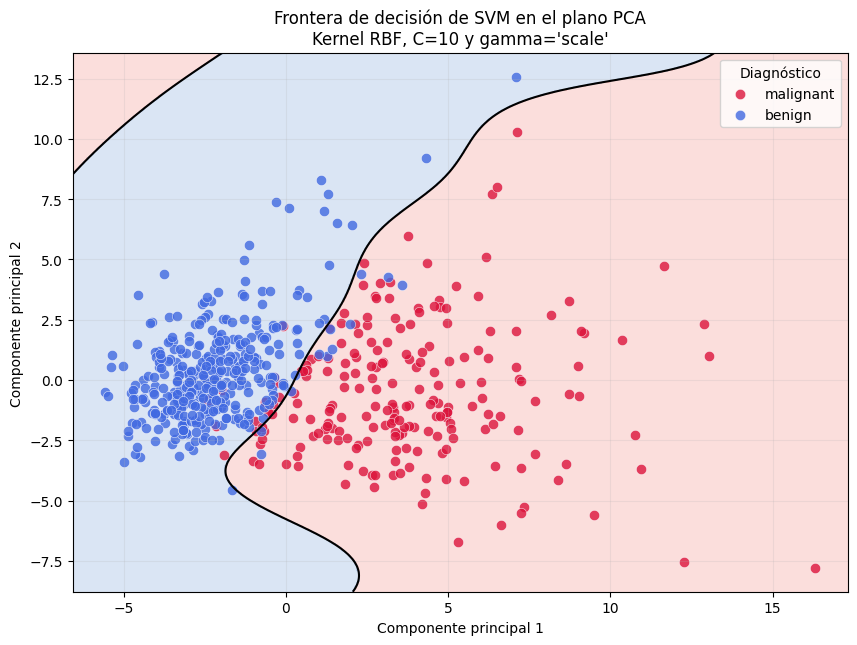

In [ ]:
from matplotlib.colors import ListedColormap

# Verificar que estén disponibles las dos componentes principales
if X_pca.shape != (569, 2):
    raise ValueError(
        "X_pca debe contener las 569 muestras "
        "y las dos componentes principales."
    )

# Extraer los parámetros elegidos, eliminando el prefijo del Pipeline
parametros_finales_svm = {
    nombre.replace("svm__", ""): valor
    for nombre, valor
    in busqueda_final_svm.best_params_.items()
}

print(
    "Parámetros utilizados en el modelo SVM 2D:",
    parametros_finales_svm
)

# Modelo adicional entrenado exclusivamente con PC1 y PC2
modelo_svm_pca = Pipeline([
    ("escalado", StandardScaler()),
    ("svm", SVC(**parametros_finales_svm))
])

modelo_svm_pca.fit(X_pca, y)

# Límites del plano PCA
pc1_min = X_pca[:, 0].min() - 1
pc1_max = X_pca[:, 0].max() + 1
pc2_min = X_pca[:, 1].min() - 1
pc2_max = X_pca[:, 1].max() + 1

# Malla para visualizar las regiones de predicción
xx, yy = np.meshgrid(
    np.linspace(pc1_min, pc1_max, 400),
    np.linspace(pc2_min, pc2_max, 400)
)

puntos_malla = np.c_[
    xx.ravel(),
    yy.ravel()
]

predicciones_malla_svm = modelo_svm_pca.predict(
    puntos_malla
).reshape(xx.shape)

# Valor de la función de decisión para dibujar la frontera exacta
decision_malla_svm = modelo_svm_pca.decision_function(
    puntos_malla
).reshape(xx.shape)

colores_fondo = ListedColormap([
    "#f7b6b2",
    "#aec7e8"
])

plt.figure(figsize=(10, 7))

# Regiones predichas
plt.contourf(
    xx,
    yy,
    predicciones_malla_svm,
    alpha=0.45,
    cmap=colores_fondo
)

# Línea de la frontera de decisión
plt.contour(
    xx,
    yy,
    decision_malla_svm,
    levels=[0],
    colors="black",
    linewidths=1.5
)

# Muestras reales
for clase, nombre, color in zip(
    [0, 1],
    target_names,
    ["crimson", "royalblue"]
):
    mascara = y == clase

    plt.scatter(
        X_pca[mascara, 0],
        X_pca[mascara, 1],
        color=color,
        label=nombre,
        edgecolor="white",
        linewidth=0.4,
        alpha=0.8,
        s=55
    )

plt.title(
    "Frontera de decisión de SVM en el plano PCA\n"
    "Kernel RBF, C=10 y gamma='scale'"
)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Diagnóstico")
plt.grid(alpha=0.2)
plt.show()

### Interpretación del modelo Support Vector Machine

Para SVM se utilizó un `Pipeline` compuesto por estandarización y el clasificador, lo que permitió ajustar el escalado exclusivamente con los datos de entrenamiento de cada partición y evitar fugas de información. Se evaluaron **68 configuraciones** de los kernels lineal, RBF, polinomial y sigmoide, variando los parámetros `C`, `gamma` y, para el kernel polinomial, `degree`. La selección se realizó mediante el F1 macro promedio en la validación interna.

La evaluación principal se efectuó con las **30 características originales** mediante validación cruzada estratificada anidada de 10 particiones externas y 5 internas. SVM obtuvo los siguientes resultados:

- Accuracy: **0.9772 ± 0.0193**
- Precision macro: **0.9780 ± 0.0187**
- Recall macro: **0.9740 ± 0.0237**
- F1 macro: **0.9753 ± 0.0210**
- MAE: **0.0228 ± 0.0193**

La matriz de confusión construida con predicciones fuera de muestra fue:

- **204** muestras malignas clasificadas correctamente.
- **8** muestras malignas clasificadas como benignas.
- **5** muestras benignas clasificadas como malignas.
- **352** muestras benignas clasificadas correctamente.

En total, el modelo realizó **556 predicciones correctas y 13 incorrectas**. Detectó correctamente aproximadamente el **96.23 % de las muestras malignas** y el **98.60 % de las benignas**.

La búsqueda final seleccionó un kernel **RBF**, `C=10` y `gamma='scale'`, con un F1 macro de búsqueda de **0.9754**. Este último valor corresponde a la búsqueda final de hiperparámetros, mientras que el F1 macro oficial para comparar y ordenar los modelos es **0.9753 ± 0.0210**, obtenido mediante validación cruzada anidada.

La frontera mostrada en el plano PCA es curva debido al uso del kernel RBF, el cual permite construir separaciones no lineales. La mayor parte de las muestras benignas se concentra en la región azul de la izquierda y las malignas en la región rosa de la derecha. Los errores visuales aparecen principalmente en la zona central, donde ambas clases se superponen.

Las regiones alejadas que contienen pocas o ninguna observación no deben interpretarse como evidencia sólida del comportamiento general del modelo. Las dos componentes principales solamente conservan aproximadamente el **63.24 % de la varianza total**: **44.27 %** en PC1 y **18.97 %** en PC2.

Esta frontera corresponde a un **modelo adicional entrenado exclusivamente con PC1 y PC2**. No es una proyección exacta de la frontera del modelo oficial entrenado con las 30 características, y sus resultados no sustituyen las métricas obtenidas mediante validación cruzada anidada.

---

## Modelo 6: Árbol de decisión

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid
)

# Verificar que seguimos usando la base de cáncer de mama
if X.shape != (569, 30):
    raise ValueError(
        "X ya no contiene la base de cáncer de mama. "
        "No ejecutes la generación de datos sintéticos "
        "del código del profesor."
    )

# Pipeline sin escalado:
# los árboles no dependen de las distancias entre variables
pipeline_arbol = Pipeline([
    (
        "arbol",
        DecisionTreeClassifier(
            random_state=42
        )
    )
])

# Hiperparámetros requeridos por el proyecto
parametros_arbol = {
    "arbol__criterion": [
        "gini",
        "entropy",
        "log_loss"
    ],

    "arbol__max_depth": [
        None,
        2,
        3,
        4,
        5,
        6,
        8,
        10
    ],

    "arbol__min_samples_split": [
        2,
        5,
        10
    ],

    "arbol__min_samples_leaf": [
        1,
        2,
        5,
        10
    ]
}

# Mismas particiones utilizadas en todos los clasificadores
cv_externa = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_interna = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

numero_configuraciones_arbol = len(
    list(ParameterGrid(parametros_arbol))
)

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

print(
    "Número de configuraciones del árbol:",
    numero_configuraciones_arbol
)

print(
    "Validación externa: "
    "10 particiones estratificadas"
)

print(
    "Validación interna: "
    "5 particiones para buscar hiperparámetros"
)

print(
    "Escalado: no se utiliza porque "
    "el árbol trabaja con reglas y umbrales"
)

Forma de X: (569, 30)
Forma de y: (569,)
Número de configuraciones del árbol: 288
Validación externa: 10 particiones estratificadas
Validación interna: 5 particiones para buscar hiperparámetros
Escalado: no se utiliza porque el árbol trabaja con reglas y umbrales


In [ ]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error
)

# Guardar resultados y predicciones fuera de muestra
resultados_arbol = []
mejores_parametros_arbol = []

predicciones_oof_arbol = np.empty_like(y)
predicciones_oof_arbol[:] = -1

# Validación cruzada externa de 10 folds
for numero_fold, (indices_train, indices_test) in enumerate(
    cv_externa.split(X, y),
    start=1
):
    X_train = X[indices_train]
    X_test = X[indices_test]
    y_train = y[indices_train]
    y_test = y[indices_test]

    # Búsqueda interna usando únicamente los datos de entrenamiento
    busqueda_arbol = GridSearchCV(
        estimator=pipeline_arbol,
        param_grid=parametros_arbol,
        scoring="f1_macro",
        cv=cv_interna,
        n_jobs=-1,
        refit=True
    )

    busqueda_arbol.fit(
        X_train,
        y_train
    )

    # Predicción sobre el fold externo
    y_pred = busqueda_arbol.predict(
        X_test
    )

    # Guardar cada predicción en la posición original
    predicciones_oof_arbol[indices_test] = y_pred

    # Métricas del fold externo
    resultados_arbol.append({
        "fold": numero_fold,

        "accuracy": accuracy_score(
            y_test,
            y_pred
        ),

        "precision_macro": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "mae": mean_absolute_error(
            y_test,
            y_pred
        )
    })

    mejores_parametros_arbol.append(
        busqueda_arbol.best_params_
    )

    print(
        f"Fold {numero_fold}/10 terminado — "
        f"mejor configuración: "
        f"{busqueda_arbol.best_params_}"
    )

# Tabla con los resultados de cada fold
resultados_arbol_df = pd.DataFrame(
    resultados_arbol
)

metricas_arbol = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "mae"
]

# Promedio y desviación estándar de las métricas
resumen_arbol_df = pd.DataFrame({
    "metrica": metricas_arbol,

    "promedio": [
        resultados_arbol_df[metrica].mean()
        for metrica in metricas_arbol
    ],

    "desviacion_estandar": [
        resultados_arbol_df[metrica].std(ddof=0)
        for metrica in metricas_arbol
    ]
})

display(
    resultados_arbol_df.round(4)
)

print(
    "\nResumen del árbol de decisión "
    "con validación cruzada anidada:"
)

display(
    resumen_arbol_df.round(4)
)

Fold 1/10 terminado — mejor configuración: {'arbol__criterion': 'entropy', 'arbol__max_depth': 4, 'arbol__min_samples_leaf': 2, 'arbol__min_samples_split': 2}
Fold 2/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': None, 'arbol__min_samples_leaf': 1, 'arbol__min_samples_split': 2}
Fold 3/10 terminado — mejor configuración: {'arbol__criterion': 'entropy', 'arbol__max_depth': 5, 'arbol__min_samples_leaf': 1, 'arbol__min_samples_split': 2}
Fold 4/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': None, 'arbol__min_samples_leaf': 1, 'arbol__min_samples_split': 2}
Fold 5/10 terminado — mejor configuración: {'arbol__criterion': 'gini', 'arbol__max_depth': 5, 'arbol__min_samples_leaf': 1, 'arbol__min_samples_split': 2}
Fold 6/10 terminado — mejor configuración: {'arbol__criterion': 'entropy', 'arbol__max_depth': 5, 'arbol__min_samples_leaf': 5, 'arbol__min_samples_split': 2}
Fold 7/10 terminado — mejor configuración: {'arbo

,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,0.9298,0.9223,0.9344,0.9271,0.0702
1,2,0.9298,0.9345,0.9175,0.9246,0.0702
2,3,0.9649,0.9623,0.9623,0.9623,0.0351
3,4,0.8947,0.9081,0.8671,0.8816,0.1053
4,5,0.9123,0.9095,0.9008,0.9048,0.0877
5,6,0.9649,0.9737,0.9524,0.9615,0.0351
6,7,0.9298,0.9201,0.9345,0.9260,0.0702
7,8,0.9474,0.9375,0.9583,0.9449,0.0526
8,9,0.9123,0.9095,0.9008,0.9048,0.0877
9,10,0.9286,0.9331,0.9143,0.9222,0.0714



Resumen del árbol de decisión con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9315,0.0214
1,precision_macro,0.9311,0.0212
2,recall_macro,0.9242,0.0285
3,f1_macro,0.9260,0.0241
4,mae,0.0685,0.0214


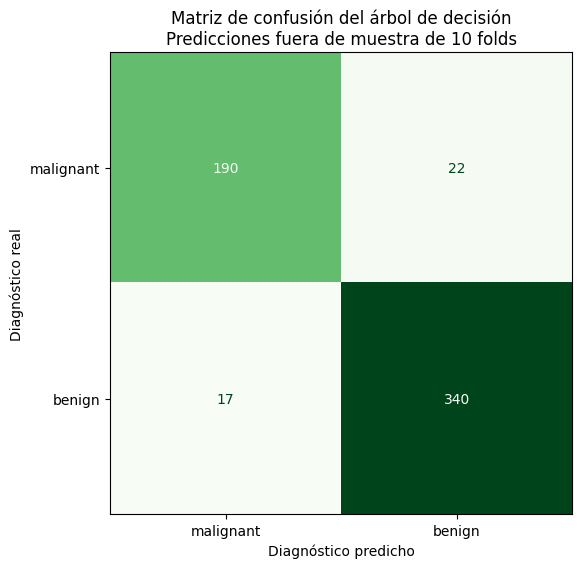

Matriz de confusión:
[[190  22]
 [ 17 340]]
Predicciones correctas: 530
Predicciones incorrectas: 39
Malignos clasificados como benignos: 22
Benignos clasificados como malignos: 17


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Verificar que todas las muestras tengan predicción
if np.any(predicciones_oof_arbol == -1):
    raise ValueError(
        "Existen muestras sin predicción fuera de muestra."
    )

# Matriz de confusión con predicciones de los folds externos
matriz_arbol = confusion_matrix(
    y,
    predicciones_oof_arbol,
    labels=[0, 1]
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_arbol,
    display_labels=target_names
)

disp.plot(
    ax=ax,
    cmap="Greens",
    values_format="d",
    colorbar=False
)

plt.title(
    "Matriz de confusión del árbol de decisión\n"
    "Predicciones fuera de muestra de 10 folds"
)

plt.xlabel("Diagnóstico predicho")
plt.ylabel("Diagnóstico real")
plt.show()

print("Matriz de confusión:")
print(matriz_arbol)

print(
    "Predicciones correctas:",
    np.trace(matriz_arbol)
)

print(
    "Predicciones incorrectas:",
    matriz_arbol.sum() - np.trace(matriz_arbol)
)

print(
    "Malignos clasificados como benignos:",
    matriz_arbol[0, 1]
)

print(
    "Benignos clasificados como malignos:",
    matriz_arbol[1, 0]
)

In [ ]:
# Búsqueda final de hiperparámetros con toda la base
busqueda_final_arbol = GridSearchCV(
    estimator=pipeline_arbol,
    param_grid=parametros_arbol,
    scoring="f1_macro",
    cv=cv_externa,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)

busqueda_final_arbol.fit(
    X,
    y
)

# Modelo final ya entrenado
mejor_modelo_arbol = (
    busqueda_final_arbol.best_estimator_
)

print("Mejores parámetros finales:")
print(
    busqueda_final_arbol.best_params_
)

print(
    "F1 macro promedio durante la búsqueda:",
    round(
        busqueda_final_arbol.best_score_,
        4
    )
)

# Resultados completos de la búsqueda
resultados_busqueda_arbol = pd.DataFrame(
    busqueda_final_arbol.cv_results_
)

columnas_busqueda_arbol = [
    "param_arbol__criterion",
    "param_arbol__max_depth",
    "param_arbol__min_samples_split",
    "param_arbol__min_samples_leaf",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

tabla_busqueda_arbol = (
    resultados_busqueda_arbol[
        columnas_busqueda_arbol
    ]
    .sort_values(
        by=[
            "rank_test_score",
            "mean_test_score"
        ],
        ascending=[
            True,
            False
        ]
    )
    .head(10)
    .reset_index(drop=True)
)

display(
    tabla_busqueda_arbol.round(4)
)

Mejores parámetros finales:
{'arbol__criterion': 'entropy', 'arbol__max_depth': None, 'arbol__min_samples_leaf': 5, 'arbol__min_samples_split': 2}
F1 macro promedio durante la búsqueda: 0.9355


,param_arbol__criterion,param_arbol__max_depth,param_arbol__min_samples_split,param_arbol__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
0,entropy,None,2,5,0.9355,0.0374,1
1,entropy,None,5,5,0.9355,0.0374,1
2,entropy,None,10,5,0.9355,0.0374,1
3,entropy,6,2,5,0.9355,0.0374,1
4,entropy,6,5,5,0.9355,0.0374,1
5,entropy,6,10,5,0.9355,0.0374,1
6,entropy,8,2,5,0.9355,0.0374,1
7,entropy,8,5,5,0.9355,0.0374,1
8,entropy,8,10,5,0.9355,0.0374,1
9,entropy,10,2,5,0.9355,0.0374,1


Profundidad real del árbol: 5
Número de hojas: 14


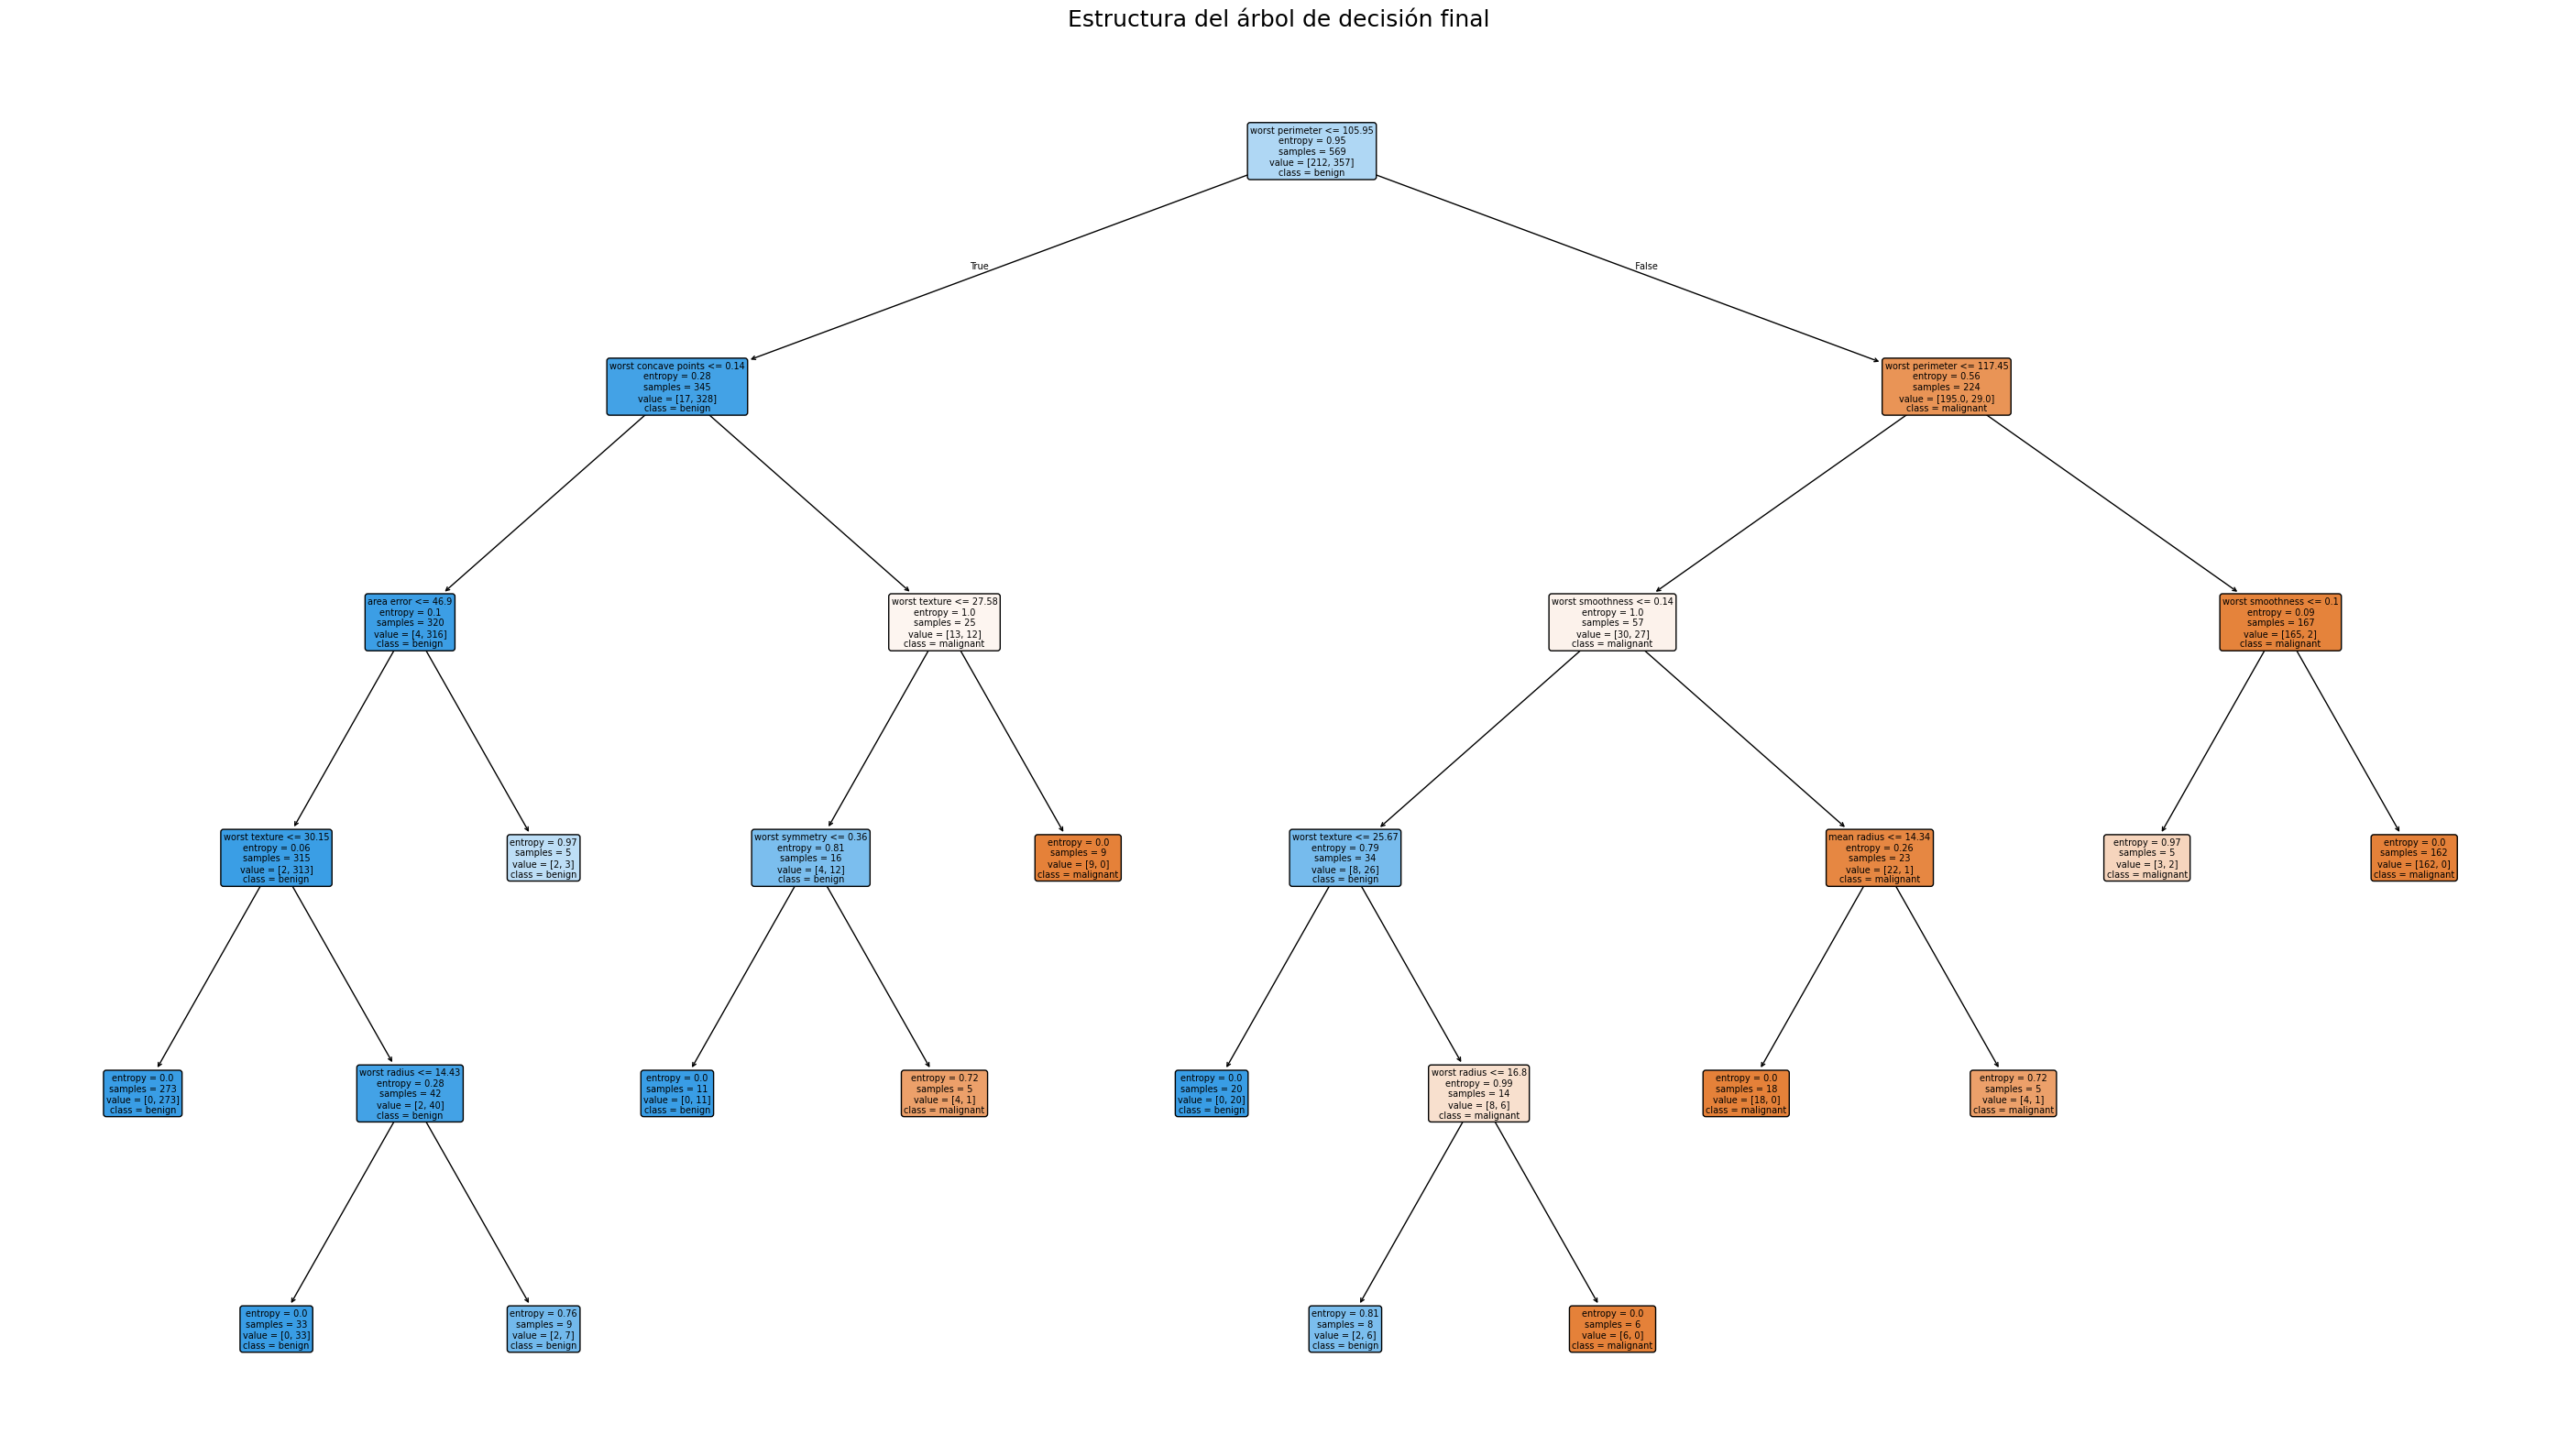

In [ ]:
from sklearn.tree import plot_tree

# Extraer el clasificador del Pipeline
arbol_final = mejor_modelo_arbol.named_steps[
    "arbol"
]

print(
    "Profundidad real del árbol:",
    arbol_final.get_depth()
)

print(
    "Número de hojas:",
    arbol_final.get_n_leaves()
)

plt.figure(
    figsize=(28, 16)
)

plot_tree(
    arbol_final,
    feature_names=feature_names,
    class_names=target_names,
    filled=True,
    rounded=True,
    proportion=False,
    precision=2,
    fontsize=7
)

plt.title(
    "Estructura del árbol de decisión final",
    fontsize=18
)

plt.tight_layout()
plt.show()

Parámetros utilizados en el árbol 2D: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 5, 'min_samples_split': 2}


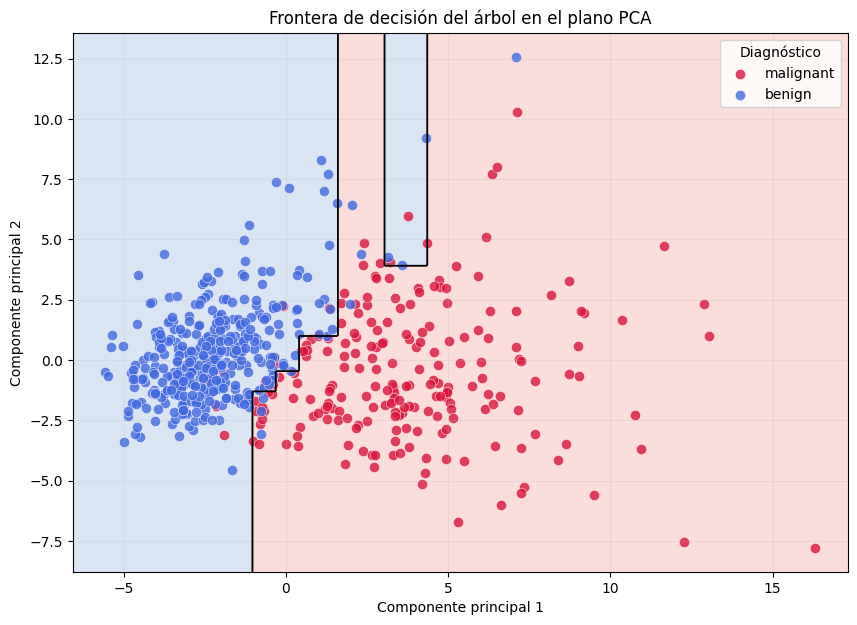

In [ ]:
from matplotlib.colors import ListedColormap

# Verificar las dimensiones del plano PCA
if X_pca.shape != (569, 2):
    raise ValueError(
        "X_pca debe contener las 569 muestras "
        "y las dos componentes principales."
    )

# Extraer los hiperparámetros seleccionados
parametros_finales_arbol = {
    nombre.replace("arbol__", ""): valor
    for nombre, valor
    in busqueda_final_arbol.best_params_.items()
}

print(
    "Parámetros utilizados en el árbol 2D:",
    parametros_finales_arbol
)

# Modelo adicional entrenado exclusivamente con PC1 y PC2
modelo_arbol_pca = DecisionTreeClassifier(
    **parametros_finales_arbol,
    random_state=42
)

modelo_arbol_pca.fit(
    X_pca,
    y
)

# Límites del plano PCA
pc1_min = X_pca[:, 0].min() - 1
pc1_max = X_pca[:, 0].max() + 1
pc2_min = X_pca[:, 1].min() - 1
pc2_max = X_pca[:, 1].max() + 1

# Malla de puntos
xx, yy = np.meshgrid(
    np.linspace(
        pc1_min,
        pc1_max,
        400
    ),
    np.linspace(
        pc2_min,
        pc2_max,
        400
    )
)

puntos_malla = np.c_[
    xx.ravel(),
    yy.ravel()
]

predicciones_malla_arbol = (
    modelo_arbol_pca
    .predict(puntos_malla)
    .reshape(xx.shape)
)

colores_fondo = ListedColormap([
    "#f7b6b2",
    "#aec7e8"
])

plt.figure(
    figsize=(10, 7)
)

# Regiones predichas
plt.contourf(
    xx,
    yy,
    predicciones_malla_arbol,
    alpha=0.45,
    cmap=colores_fondo
)

# Líneas que separan las regiones
plt.contour(
    xx,
    yy,
    predicciones_malla_arbol,
    levels=[0.5],
    colors="black",
    linewidths=1.3
)

# Muestras reales
for clase, nombre, color in zip(
    [0, 1],
    target_names,
    ["crimson", "royalblue"]
):
    mascara = y == clase

    plt.scatter(
        X_pca[mascara, 0],
        X_pca[mascara, 1],
        color=color,
        label=nombre,
        edgecolor="white",
        linewidth=0.4,
        alpha=0.8,
        s=55
    )

plt.title(
    "Frontera de decisión del árbol "
    "en el plano PCA"
)

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Diagnóstico")
plt.grid(alpha=0.2)
plt.show()

### Interpretación del árbol de decisión

El árbol de decisión se entrenó sin estandarización, ya que este algoritmo realiza divisiones mediante reglas y umbrales sobre las características y no depende de distancias ni de la escala de las variables.

Se probaron **288 configuraciones**, variando el criterio de impureza, la profundidad máxima, el número mínimo de muestras necesarias para dividir un nodo y el número mínimo de muestras permitido en una hoja. La configuración se seleccionó mediante F1 macro en la validación interna.

La evaluación principal se realizó con las **30 características originales**, utilizando validación cruzada estratificada anidada de 10 particiones externas y 5 internas. Los resultados fueron:

- Accuracy: **0.9315 ± 0.0214**
- Precision macro: **0.9311 ± 0.0212**
- Recall macro: **0.9242 ± 0.0285**
- F1 macro: **0.9260 ± 0.0241**
- MAE: **0.0685 ± 0.0214**

La matriz de confusión construida con predicciones fuera de muestra fue:

- **190** muestras malignas clasificadas correctamente.
- **22** muestras malignas clasificadas como benignas.
- **17** muestras benignas clasificadas como malignas.
- **340** muestras benignas clasificadas correctamente.

En total, el árbol produjo **530 predicciones correctas y 39 incorrectas**. Reconoció aproximadamente el **89.62 % de las muestras malignas** y el **95.24 % de las benignas**.

La búsqueda final seleccionó los siguientes parámetros:

- Criterio: **entropy**
- Profundidad máxima: **sin límite explícito**
- Mínimo de muestras por hoja: **5**
- Mínimo de muestras para dividir un nodo: **2**

El F1 macro obtenido durante esta búsqueda final fue **0.9355**. Este valor se utilizó para seleccionar el modelo definitivo; el valor oficial para comparar y ordenar los clasificadores es **0.9260 ± 0.0241**, procedente de la validación cruzada anidada.

La estructura del árbol muestra que la primera división se realizó mediante `worst perimeter`, seguida por características como `worst concave points`, `worst texture`, `worst smoothness`, `worst radius` y `mean radius`. Esto permite interpretar directamente algunas de las reglas empleadas por el clasificador.

La frontera en el plano PCA presenta regiones rectangulares y escalonadas porque el árbol divide una característica a la vez mediante umbrales paralelos a los ejes. La mayoría de las muestras benignas se encuentra en la región izquierda y las malignas en la derecha, aunque existe superposición cerca de la zona central. Algunas regiones pequeñas muestran que el árbol puede crear reglas locales para grupos reducidos, lo cual aumenta su capacidad de ajuste, pero también puede reducir su estabilidad frente a datos nuevos.

Las dos componentes principales representan aproximadamente el **63.24 % de la varianza total**: **44.27 %** corresponde a PC1 y **18.97 %** a PC2. Esta frontera pertenece a un **modelo adicional entrenado exclusivamente con PC1 y PC2** y no es una proyección exacta de la frontera del árbol evaluado con las 30 características originales.

Aunque el árbol ofrece una interpretación más directa de sus decisiones, su desempeño fue inferior al de k-NN y SVM, posiblemente debido a la sensibilidad de un único árbol a pequeñas variaciones en los datos y a sus divisiones paralelas a los ejes.

---

## Modelo 7: Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    ParameterGrid
)

# Verificar que seguimos usando la base de cáncer
if X.shape != (569, 30):
    raise ValueError(
        "X ya no contiene la base de cáncer de mama. "
        "No ejecutes la generación de datos sintéticos "
        "del código del profesor."
    )

# Random Forest no necesita estandarización
pipeline_bosque = Pipeline([
    (
        "bosque",
        RandomForestClassifier(
            bootstrap=True,
            random_state=42,
            n_jobs=1
        )
    )
])

# Hiperparámetros requeridos por el proyecto
parametros_bosque = {
    # Número de árboles
    "bosque__n_estimators": [
        100,
        300,
        500
    ],

    # Profundidad de los árboles
    "bosque__max_depth": [
        None,
        5,
        10
    ],

    # Características consideradas en cada división
    "bosque__max_features": [
        "sqrt",
        "log2",
        None
    ],

    # Criterio de calidad de las divisiones
    "bosque__criterion": [
        "gini",
        "entropy"
    ]
}

# Mismas particiones de los modelos anteriores
cv_externa = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_interna = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

numero_configuraciones_bosque = len(
    list(
        ParameterGrid(
            parametros_bosque
        )
    )
)

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

print(
    "Número de configuraciones "
    "de Random Forest:",
    numero_configuraciones_bosque
)

print(
    "Validación externa: "
    "10 particiones estratificadas"
)

print(
    "Validación interna: "
    "5 particiones para buscar hiperparámetros"
)

print(
    "Escalado: no se utiliza porque "
    "Random Forest trabaja con reglas y umbrales"
)

print(
    "OOB no se utilizará como evaluación oficial; "
    "el rendimiento se medirá con folds externos"
)

Forma de X: (569, 30)
Forma de y: (569,)
Número de configuraciones de Random Forest: 54
Validación externa: 10 particiones estratificadas
Validación interna: 5 particiones para buscar hiperparámetros
Escalado: no se utiliza porque Random Forest trabaja con reglas y umbrales
OOB no se utilizará como evaluación oficial; el rendimiento se medirá con folds externos


In [ ]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error
)

# Guardar resultados y predicciones fuera de muestra
resultados_bosque = []
mejores_parametros_bosque = []

predicciones_oof_bosque = np.empty_like(y)
predicciones_oof_bosque[:] = -1

# Validación cruzada externa de 10 folds
for numero_fold, (indices_train, indices_test) in enumerate(
    cv_externa.split(X, y),
    start=1
):
    X_train = X[indices_train]
    X_test = X[indices_test]
    y_train = y[indices_train]
    y_test = y[indices_test]

    # Búsqueda interna de hiperparámetros
    busqueda_bosque = GridSearchCV(
        estimator=pipeline_bosque,
        param_grid=parametros_bosque,
        scoring="f1_macro",
        cv=cv_interna,
        n_jobs=-1,
        refit=True
    )

    # La búsqueda utiliza solamente el fold de entrenamiento
    busqueda_bosque.fit(
        X_train,
        y_train
    )

    # Predicción sobre el fold externo
    y_pred = busqueda_bosque.predict(
        X_test
    )

    # Guardar predicciones en sus posiciones originales
    predicciones_oof_bosque[
        indices_test
    ] = y_pred

    # Métricas del fold externo
    resultados_bosque.append({
        "fold": numero_fold,

        "accuracy": accuracy_score(
            y_test,
            y_pred
        ),

        "precision_macro": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "mae": mean_absolute_error(
            y_test,
            y_pred
        )
    })

    mejores_parametros_bosque.append(
        busqueda_bosque.best_params_
    )

    print(
        f"Fold {numero_fold}/10 terminado — "
        f"mejor configuración: "
        f"{busqueda_bosque.best_params_}"
    )

# Tabla de resultados por fold
resultados_bosque_df = pd.DataFrame(
    resultados_bosque
)

metricas_bosque = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "mae"
]

# Promedios y desviaciones estándar
resumen_bosque_df = pd.DataFrame({
    "metrica": metricas_bosque,

    "promedio": [
        resultados_bosque_df[metrica].mean()
        for metrica in metricas_bosque
    ],

    "desviacion_estandar": [
        resultados_bosque_df[metrica].std(ddof=0)
        for metrica in metricas_bosque
    ]
})

display(
    resultados_bosque_df.round(4)
)

print(
    "\nResumen de Random Forest "
    "con validación cruzada anidada:"
)

display(
    resumen_bosque_df.round(4)
)

Fold 1/10 terminado — mejor configuración: {'bosque__criterion': 'entropy', 'bosque__max_depth': None, 'bosque__max_features': 'log2', 'bosque__n_estimators': 100}
Fold 2/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': None, 'bosque__max_features': None, 'bosque__n_estimators': 300}
Fold 3/10 terminado — mejor configuración: {'bosque__criterion': 'entropy', 'bosque__max_depth': None, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 300}
Fold 4/10 terminado — mejor configuración: {'bosque__criterion': 'entropy', 'bosque__max_depth': None, 'bosque__max_features': 'log2', 'bosque__n_estimators': 100}
Fold 5/10 terminado — mejor configuración: {'bosque__criterion': 'gini', 'bosque__max_depth': None, 'bosque__max_features': None, 'bosque__n_estimators': 500}
Fold 6/10 terminado — mejor configuración: {'bosque__criterion': 'entropy', 'bosque__max_depth': None, 'bosque__max_features': 'sqrt', 'bosque__n_estimators': 100}
Fold 7/10 terminado — mejo

,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,0.9474,0.9418,0.9487,0.9449,0.0526
1,2,0.9649,0.9630,0.9630,0.9630,0.0351
2,3,0.9825,0.9865,0.9762,0.9810,0.0175
3,4,0.8596,0.8662,0.8294,0.8421,0.1404
4,5,0.9474,0.9480,0.9385,0.9429,0.0526
5,6,0.9825,0.9865,0.9762,0.9810,0.0175
6,7,0.9649,0.9623,0.9623,0.9623,0.0351
7,8,0.9649,0.9565,0.9722,0.9630,0.0351
8,9,0.9298,0.9342,0.9147,0.9230,0.0702
9,10,1.0000,1.0000,1.0000,1.0000,0.0000



Resumen de Random Forest con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9544,0.0370
1,precision_macro,0.9545,0.0356
2,recall_macro,0.9481,0.0454
3,f1_macro,0.9503,0.0417
4,mae,0.0456,0.0370


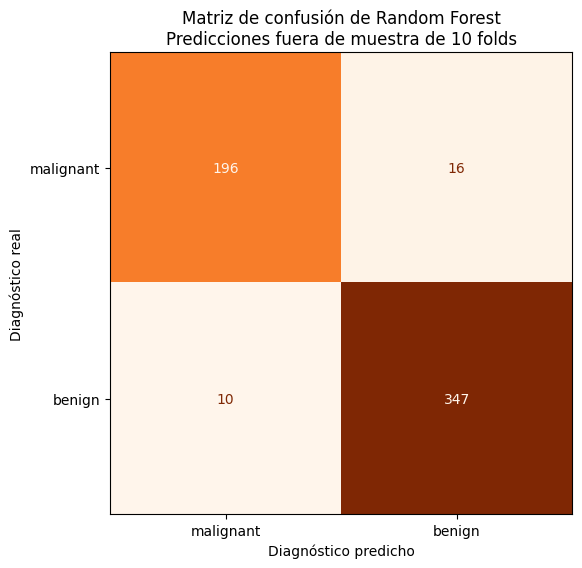

Matriz de confusión:
[[196  16]
 [ 10 347]]
Predicciones correctas: 543
Predicciones incorrectas: 26
Malignos clasificados como benignos: 16
Benignos clasificados como malignos: 10


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Verificar que todas las muestras tengan predicción
if np.any(predicciones_oof_bosque == -1):
    raise ValueError(
        "Existen muestras sin predicción fuera de muestra."
    )

# Matriz de confusión con predicciones de los folds externos
matriz_bosque = confusion_matrix(
    y,
    predicciones_oof_bosque,
    labels=[0, 1]
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_bosque,
    display_labels=target_names
)

disp.plot(
    ax=ax,
    cmap="Oranges",
    values_format="d",
    colorbar=False
)

plt.title(
    "Matriz de confusión de Random Forest\n"
    "Predicciones fuera de muestra de 10 folds"
)

plt.xlabel("Diagnóstico predicho")
plt.ylabel("Diagnóstico real")
plt.show()

print("Matriz de confusión:")
print(matriz_bosque)

print(
    "Predicciones correctas:",
    np.trace(matriz_bosque)
)

print(
    "Predicciones incorrectas:",
    matriz_bosque.sum()
    - np.trace(matriz_bosque)
)

print(
    "Malignos clasificados como benignos:",
    matriz_bosque[0, 1]
)

print(
    "Benignos clasificados como malignos:",
    matriz_bosque[1, 0]
)

In [ ]:
# Modelo final de Random Forest
# Configuración seleccionada a partir de los resultados
# de la validación cruzada anidada ya realizada

mejores_parametros_bosque = {
    "n_estimators": 300,
    "criterion": "entropy",
    "max_depth": None,
    "max_features": "sqrt"
}

modelo_final_bosque = RandomForestClassifier(
    **mejores_parametros_bosque,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Se entrena con toda la base únicamente para interpretación,
# importancia de variables y visualizaciones posteriores.
# Las métricas oficiales siguen siendo las de los folds externos.
modelo_final_bosque.fit(X, y)

print("Parámetros del modelo final:")
print(mejores_parametros_bosque)

print("\nResultados oficiales de validación cruzada anidada:")
print("Accuracy:        0.9544 ± 0.0370")
print("Precision macro: 0.9545 ± 0.0356")
print("Recall macro:    0.9481 ± 0.0454")
print("F1 macro:        0.9503 ± 0.0417")
print("MAE:             0.0456 ± 0.0370")

Parámetros del modelo final:
{'n_estimators': 300, 'criterion': 'entropy', 'max_depth': None, 'max_features': 'sqrt'}

Resultados oficiales de validación cruzada anidada:
Accuracy:        0.9544 ± 0.0370
Precision macro: 0.9545 ± 0.0356
Recall macro:    0.9481 ± 0.0454
F1 macro:        0.9503 ± 0.0417
MAE:             0.0456 ± 0.0370


Las 10 características más importantes:


,caracteristica,importancia
0,worst perimeter,0.1428
1,worst area,0.1339
2,worst concave points,0.1176
3,mean concave points,0.0898
4,worst radius,0.0688
5,mean concavity,0.0466
6,mean perimeter,0.0457
7,mean radius,0.0456
8,worst concavity,0.0444
9,mean area,0.0427


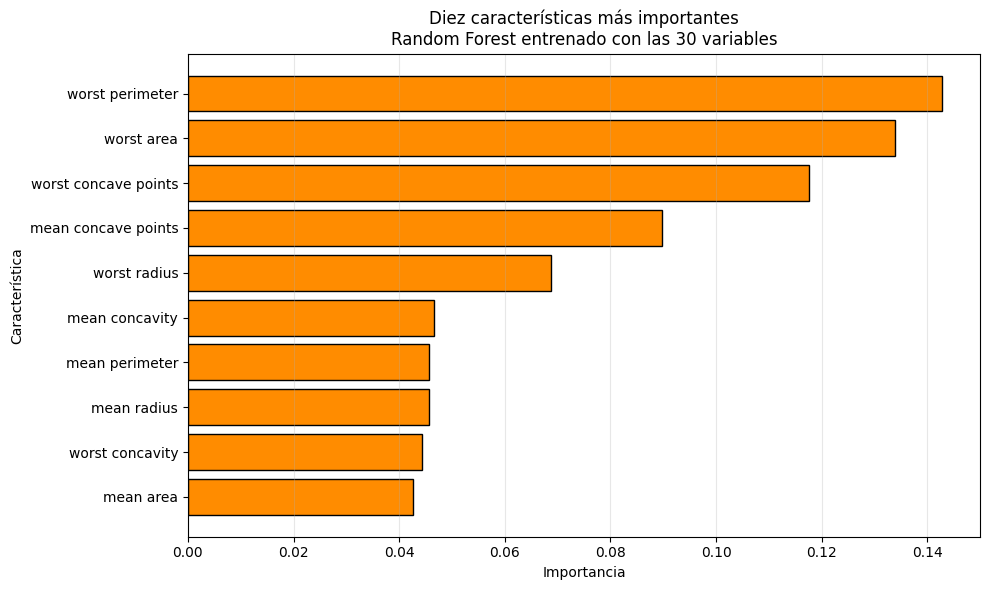

Suma de las importancias: 1.0


In [ ]:
# Importancia de las características del Random Forest final

importancias_bosque = modelo_final_bosque.feature_importances_

tabla_importancias_bosque = pd.DataFrame({
    "caracteristica": feature_names,
    "importancia": importancias_bosque
}).sort_values(
    by="importancia",
    ascending=False
).reset_index(drop=True)

print("Las 10 características más importantes:")
display(tabla_importancias_bosque.head(10).round(4))

# Gráfica de las 10 características más importantes
top_10_bosque = tabla_importancias_bosque.head(10).sort_values(
    by="importancia",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_bosque["caracteristica"],
    top_10_bosque["importancia"],
    color="darkorange",
    edgecolor="black"
)

plt.title(
    "Diez características más importantes\n"
    "Random Forest entrenado con las 30 variables"
)
plt.xlabel("Importancia")
plt.ylabel("Característica")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Suma de las importancias:",
    round(importancias_bosque.sum(), 4)
)

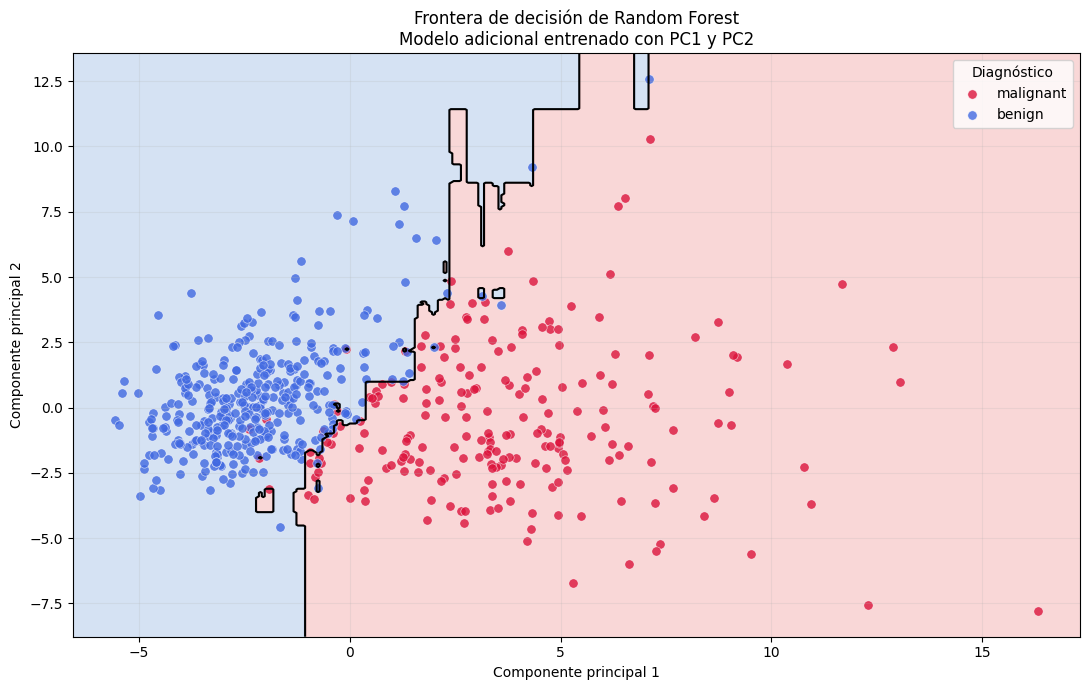

Advertencia: esta frontera pertenece a un modelo entrenado exclusivamente con PC1 y PC2.
No es una proyección exacta de la frontera del modelo evaluado con las 30 características originales.


In [ ]:
# Frontera de decisión de Random Forest en el plano PCA
# Este es un modelo adicional entrenado únicamente con PC1 y PC2.

from matplotlib.colors import ListedColormap

modelo_bosque_pca = RandomForestClassifier(
    **mejores_parametros_bosque,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

modelo_bosque_pca.fit(X_pca, y)

# Límites del plano PCA
margen = 1
x_min = X_pca[:, 0].min() - margen
x_max = X_pca[:, 0].max() + margen
y_min = X_pca[:, 1].min() - margen
y_max = X_pca[:, 1].max() + margen

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 350),
    np.linspace(y_min, y_max, 350)
)

puntos_malla = np.c_[xx.ravel(), yy.ravel()]
predicciones_malla = modelo_bosque_pca.predict(
    puntos_malla
).reshape(xx.shape)

colores_fondo = ListedColormap(["#f8caca", "#c8d9f0"])
colores_puntos = ["crimson", "royalblue"]

plt.figure(figsize=(11, 7))

plt.contourf(
    xx,
    yy,
    predicciones_malla,
    cmap=colores_fondo,
    alpha=0.75
)

# Línea que separa ambas regiones
plt.contour(
    xx,
    yy,
    predicciones_malla,
    levels=[0.5],
    colors="black",
    linewidths=1.5
)

for clase, nombre, color in zip(
    [0, 1],
    target_names,
    colores_puntos
):
    plt.scatter(
        X_pca[y == clase, 0],
        X_pca[y == clase, 1],
        c=color,
        label=nombre,
        edgecolor="white",
        linewidth=0.4,
        alpha=0.8,
        s=45
    )

plt.title(
    "Frontera de decisión de Random Forest\n"
    "Modelo adicional entrenado con PC1 y PC2"
)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Diagnóstico")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "Advertencia: esta frontera pertenece a un modelo entrenado "
    "exclusivamente con PC1 y PC2."
)
print(
    "No es una proyección exacta de la frontera del modelo "
    "evaluado con las 30 características originales."
)

### Interpretación de Random Forest

Random Forest se evaluó utilizando las 30 características originales de la base de cáncer de mama mediante validación cruzada anidada. La búsqueda interna exploró 54 combinaciones de número de árboles, profundidad máxima, criterio de división y cantidad de características consideradas en cada división. Las métricas oficiales obtenidas en los 10 folds externos fueron: accuracy de 0.9544 ± 0.0370, precisión macro de 0.9545 ± 0.0356, recall macro de 0.9481 ± 0.0454, F1 macro de 0.9503 ± 0.0417 y MAE de 0.0456 ± 0.0370.

La matriz de confusión construida con predicciones fuera de muestra registró 543 clasificaciones correctas y 26 incorrectas. El modelo identificó correctamente 196 tumores malignos y 347 benignos. Sin embargo, clasificó 16 casos malignos como benignos y 10 casos benignos como malignos. En una aplicación médica, los 16 casos malignos no detectados representan el error de mayor importancia.

Como configuración final se seleccionaron 300 árboles, criterio entropy, profundidad sin límite y `max_features="sqrt"`. Las características con mayor importancia fueron `worst perimeter`, `worst area`, `worst concave points`, `mean concave points` y `worst radius`. Esto indica que el tamaño del tumor y la irregularidad de su contorno fueron especialmente relevantes para las decisiones del bosque.

La frontera mostrada en el plano PCA corresponde a un modelo adicional entrenado exclusivamente con PC1 y PC2. Su forma escalonada se debe a las divisiones mediante umbrales realizadas por los árboles. Esta visualización permite analizar la separación aproximada entre las clases, pero no representa una proyección exacta de la frontera del modelo evaluado con las 30 características originales. Las dos componentes principales explican conjuntamente el 63.24 % de la varianza total, por lo que parte de la información original no aparece en esta gráfica.

---

## Modelo 8: Multilayer Perceptron (MLP)

Evaluación del clasificador MLP utilizando las 30 características originales, escalado dentro del pipeline, búsqueda de hiperparámetros y validación cruzada estratificada.

In [ ]:
# Configuración inicial para Multilayer Perceptron (MLP)

from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

# Verificar que seguimos trabajando con cáncer de mama
print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

if X.shape != (569, 30):
    raise ValueError(
        "X ya no contiene la base de cáncer de mama. "
        "No ejecutes la generación de datos sintéticos del profesor."
    )

# El escalado es indispensable para entrenar correctamente una red neuronal
pipeline_mlp = Pipeline([
    ("escalado", StandardScaler()),
    ("mlp", MLPClassifier(
        solver="adam",
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=20,
        random_state=42
    ))
])

# Espacio de hiperparámetros
parametros_mlp = {
    # Arquitectura: capas ocultas y neuronas
    "mlp__hidden_layer_sizes": [
        (20,),
        (50,),
        (100,),
        (30, 15),
        (50, 25),
        (50, 25, 10)
    ],

    # Función de activación
    "mlp__activation": [
        "relu",
        "tanh",
        "logistic"
    ],

    # Regularización L2
    "mlp__alpha": loguniform(1e-5, 1e-1),

    # Tasa de aprendizaje inicial
    "mlp__learning_rate_init": loguniform(1e-4, 1e-2)
}

print("\nConfiguración del MLP:")
print("- Escalado dentro del pipeline")
print("- Optimizador: Adam")
print("- Early stopping activado")
print("- Máximo de iteraciones: 1000")
print("- Se buscarán capas, neuronas, activación, regularización")
print("  y tasa de aprendizaje")


Forma de X: (569, 30)
Forma de y: (569,)

Configuración del MLP:
- Escalado dentro del pipeline
- Optimizador: Adam
- Early stopping activado
- Máximo de iteraciones: 1000
- Se buscarán capas, neuronas, activación, regularización
  y tasa de aprendizaje


In [ ]:
# Validación cruzada anidada para MLP
# 10 folds externos y 5 folds internos

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error
)

resultados_folds_mlp = []
mejores_parametros_folds_mlp = []

# Predicciones fuera de muestra
predicciones_oof_mlp = np.empty_like(y)

print("Validación externa: 10 particiones estratificadas")
print("Validación interna: 5 particiones")
print("Configuraciones aleatorias por fold: 8")
print("Total aproximado de entrenamientos: 400\n")

for numero_fold, (indices_train, indices_test) in enumerate(
    cv_externa.split(X, y),
    start=1
):
    X_train = X[indices_train]
    X_test = X[indices_test]
    y_train = y[indices_train]
    y_test = y[indices_test]

    busqueda_mlp = RandomizedSearchCV(
        estimator=clone(pipeline_mlp),
        param_distributions=parametros_mlp,
        n_iter=8,
        scoring="f1_macro",
        cv=cv_interna,
        random_state=42,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    # La búsqueda se ajusta únicamente con el entrenamiento externo
    busqueda_mlp.fit(X_train, y_train)

    mejor_modelo_fold = busqueda_mlp.best_estimator_
    y_pred = mejor_modelo_fold.predict(X_test)

    predicciones_oof_mlp[indices_test] = y_pred
    mejores_parametros_folds_mlp.append(
        busqueda_mlp.best_params_
    )

    resultados_folds_mlp.append({
        "fold": numero_fold,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_macro": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "recall_macro": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "mae": mean_absolute_error(y_test, y_pred)
    })

    print(
        f"Fold {numero_fold}/10 terminado — "
        f"mejor configuración: {busqueda_mlp.best_params_}"
    )

# Tabla de resultados por fold
tabla_folds_mlp = pd.DataFrame(resultados_folds_mlp)

display(tabla_folds_mlp.round(4))

# Resumen de promedio y desviación estándar
metricas_mlp = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
    "mae"
]

resumen_mlp = pd.DataFrame({
    "metrica": metricas_mlp,
    "promedio": [
        tabla_folds_mlp[metrica].mean()
        for metrica in metricas_mlp
    ],
    "desviacion_estandar": [
        tabla_folds_mlp[metrica].std(ddof=0)
        for metrica in metricas_mlp
    ]
})

print("\nResumen de MLP con validación cruzada anidada:")
display(resumen_mlp.round(4))

Validación externa: 10 particiones estratificadas
Validación interna: 5 particiones
Configuraciones aleatorias por fold: 8
Total aproximado de entrenamientos: 400

Fold 1/10 terminado — mejor configuración: {'mlp__activation': 'logistic', 'mlp__alpha': np.float64(0.015352246941973482), 'mlp__hidden_layer_sizes': (100,), 'mlp__learning_rate_init': np.float64(0.0036256176345762273)}
Fold 2/10 terminado — mejor configuración: {'mlp__activation': 'logistic', 'mlp__alpha': np.float64(0.015352246941973482), 'mlp__hidden_layer_sizes': (100,), 'mlp__learning_rate_init': np.float64(0.0036256176345762273)}
Fold 3/10 terminado — mejor configuración: {'mlp__activation': 'logistic', 'mlp__alpha': np.float64(0.015352246941973482), 'mlp__hidden_layer_sizes': (100,), 'mlp__learning_rate_init': np.float64(0.0036256176345762273)}
Fold 4/10 terminado — mejor configuración: {'mlp__activation': 'logistic', 'mlp__alpha': np.float64(1.2087541473056957e-05), 'mlp__hidden_layer_sizes': (50,), 'mlp__learning_ra

,fold,accuracy,precision_macro,recall_macro,f1_macro,mae
0,1,0.9825,0.9861,0.9773,0.9813,0.0175
1,2,0.9649,0.9630,0.9630,0.9630,0.0351
2,3,0.9825,0.9865,0.9762,0.9810,0.0175
3,4,0.8947,0.9286,0.8571,0.8782,0.1053
4,5,0.9649,0.9737,0.9524,0.9615,0.0351
5,6,0.9474,0.9615,0.9286,0.9415,0.0526
6,7,0.9649,0.9737,0.9524,0.9615,0.0351
7,8,0.9649,0.9565,0.9722,0.9630,0.0351
8,9,0.9825,0.9865,0.9762,0.9810,0.0175
9,10,0.9643,0.9730,0.9524,0.9611,0.0357



Resumen de MLP con validación cruzada anidada:


,metrica,promedio,desviacion_estandar
0,accuracy,0.9613,0.0246
1,precision_macro,0.9689,0.0169
2,recall_macro,0.9508,0.0345
3,f1_macro,0.9573,0.0288
4,mae,0.0387,0.0246


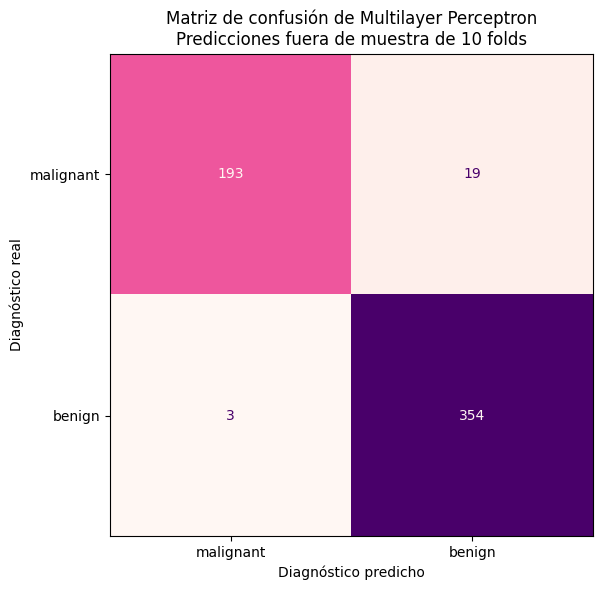

Matriz de confusión:
[[193  19]
 [  3 354]]

Predicciones correctas: 547
Predicciones incorrectas: 22
Malignos clasificados como benignos: 19
Benignos clasificados como malignos: 3


In [ ]:
# Matriz de confusión del MLP
# Construida con predicciones fuera de muestra de los 10 folds

matriz_mlp = confusion_matrix(
    y,
    predicciones_oof_mlp,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_mlp,
    display_labels=target_names
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap="RdPu",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title(
    "Matriz de confusión de Multilayer Perceptron\n"
    "Predicciones fuera de muestra de 10 folds"
)
plt.xlabel("Diagnóstico predicho")
plt.ylabel("Diagnóstico real")
plt.tight_layout()
plt.show()

correctas_mlp = np.trace(matriz_mlp)
incorrectas_mlp = matriz_mlp.sum() - correctas_mlp

print("Matriz de confusión:")
print(matriz_mlp)

print("\nPredicciones correctas:", correctas_mlp)
print("Predicciones incorrectas:", incorrectas_mlp)

print(
    "Malignos clasificados como benignos:",
    matriz_mlp[0, 1]
)

print(
    "Benignos clasificados como malignos:",
    matriz_mlp[1, 0]
)

In [ ]:
# Seleccionar la configuración más frecuente de los folds externos

from collections import Counter
from sklearn.base import clone

def convertir_valor(valor):
    """Convierte valores de NumPy a tipos normales de Python."""
    if isinstance(valor, np.floating):
        return float(valor)
    if isinstance(valor, np.integer):
        return int(valor)
    return valor

# Convertir cada diccionario en una estructura que pueda contarse
configuraciones_normalizadas = []

for parametros in mejores_parametros_folds_mlp:
    configuracion = tuple(sorted(
        (
            nombre,
            convertir_valor(valor)
        )
        for nombre, valor in parametros.items()
    ))

    configuraciones_normalizadas.append(configuracion)

conteo_configuraciones_mlp = Counter(
    configuraciones_normalizadas
)

configuracion_mas_frecuente, frecuencia_mlp = (
    conteo_configuraciones_mlp.most_common(1)[0]
)

mejores_parametros_mlp = dict(
    configuracion_mas_frecuente
)

print("Configuraciones seleccionadas durante los 10 folds:\n")

for configuracion, frecuencia in conteo_configuraciones_mlp.most_common():
    print(f"Frecuencia: {frecuencia}")
    print(dict(configuracion))
    print()

print("Configuración final seleccionada:")
print(mejores_parametros_mlp)

print(
    "\nEsta configuración fue seleccionada en",
    frecuencia_mlp,
    "de los 10 folds."
)

# Entrenamiento final con las 30 características
# Este ajuste se usa para inspección y aplicaciones posteriores.
# Las métricas oficiales siguen siendo las de los folds externos.

modelo_final_mlp = clone(pipeline_mlp)
modelo_final_mlp.set_params(**mejores_parametros_mlp)
modelo_final_mlp.fit(X, y)

print("\nModelo final entrenado correctamente.")
print("Número de iteraciones utilizadas:")
print(modelo_final_mlp.named_steps["mlp"].n_iter_)

Configuraciones seleccionadas durante los 10 folds:

Frecuencia: 8
{'mlp__activation': 'logistic', 'mlp__alpha': 0.015352246941973482, 'mlp__hidden_layer_sizes': (100,), 'mlp__learning_rate_init': 0.0036256176345762273}

Frecuencia: 2
{'mlp__activation': 'logistic', 'mlp__alpha': 1.2087541473056957e-05, 'mlp__hidden_layer_sizes': (50,), 'mlp__learning_rate_init': 0.0027796975515266818}

Configuración final seleccionada:
{'mlp__activation': 'logistic', 'mlp__alpha': 0.015352246941973482, 'mlp__hidden_layer_sizes': (100,), 'mlp__learning_rate_init': 0.0036256176345762273}

Esta configuración fue seleccionada en 8 de los 10 folds.

Modelo final entrenado correctamente.
Número de iteraciones utilizadas:
42


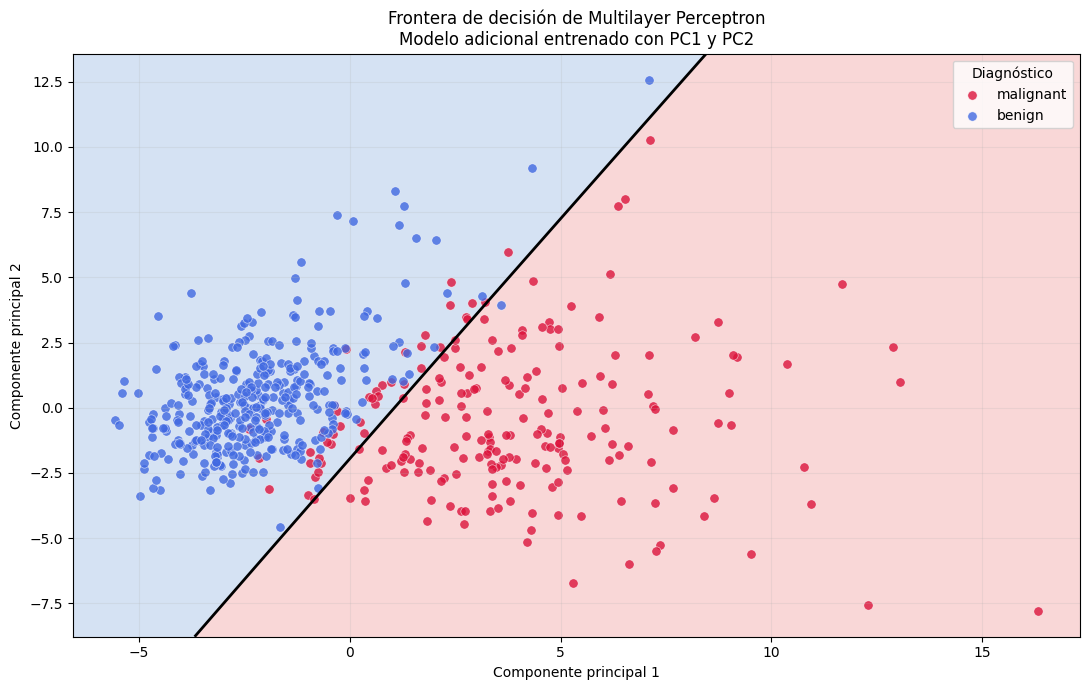

Advertencia: esta frontera corresponde a un modelo entrenado exclusivamente con PC1 y PC2.
No es una proyección exacta de la frontera del MLP evaluado con las 30 características.


In [ ]:
# Frontera de decisión del MLP en el plano PCA
# Modelo adicional entrenado exclusivamente con PC1 y PC2

from matplotlib.colors import ListedColormap
from sklearn.base import clone

modelo_mlp_pca = clone(pipeline_mlp)
modelo_mlp_pca.set_params(**mejores_parametros_mlp)

# Entrenamiento exclusivo con las dos componentes
modelo_mlp_pca.fit(X_pca, y)

# Crear la malla del plano PCA
margen = 1

x_min = X_pca[:, 0].min() - margen
x_max = X_pca[:, 0].max() + margen
y_min = X_pca[:, 1].min() - margen
y_max = X_pca[:, 1].max() + margen

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 350),
    np.linspace(y_min, y_max, 350)
)

puntos_malla = np.c_[xx.ravel(), yy.ravel()]

# Probabilidad de pertenecer a la clase benign
probabilidad_benigno = modelo_mlp_pca.predict_proba(
    puntos_malla
)[:, 1].reshape(xx.shape)

colores_fondo = ListedColormap([
    "#f8caca",
    "#c8d9f0"
])

plt.figure(figsize=(11, 7))

# Regiones clasificadas
plt.contourf(
    xx,
    yy,
    probabilidad_benigno >= 0.5,
    cmap=colores_fondo,
    alpha=0.75
)

# Frontera con probabilidad igual a 0.5
plt.contour(
    xx,
    yy,
    probabilidad_benigno,
    levels=[0.5],
    colors="black",
    linewidths=2
)

# Datos reales
for clase, nombre, color in zip(
    [0, 1],
    target_names,
    ["crimson", "royalblue"]
):
    plt.scatter(
        X_pca[y == clase, 0],
        X_pca[y == clase, 1],
        c=color,
        label=nombre,
        edgecolor="white",
        linewidth=0.4,
        alpha=0.8,
        s=45
    )

plt.title(
    "Frontera de decisión de Multilayer Perceptron\n"
    "Modelo adicional entrenado con PC1 y PC2"
)
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Diagnóstico")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "Advertencia: esta frontera corresponde a un modelo "
    "entrenado exclusivamente con PC1 y PC2."
)
print(
    "No es una proyección exacta de la frontera del MLP "
    "evaluado con las 30 características."
)

### Interpretación de Multilayer Perceptron

El clasificador Multilayer Perceptron se evaluó utilizando las 30 características originales mediante validación cruzada anidada. El escalado se incorporó dentro del pipeline para evitar fugas de información, ya que el entrenamiento de una red neuronal es sensible a las diferencias de escala entre variables. En cada fold externo se realizó una búsqueda interna limitada de arquitecturas, funciones de activación, regularización y tasas de aprendizaje.

Las métricas oficiales obtenidas fueron: accuracy de 0.9613 ± 0.0246, precisión macro de 0.9689 ± 0.0169, recall macro de 0.9508 ± 0.0345, F1 macro de 0.9573 ± 0.0288 y MAE de 0.0387 ± 0.0246. Estos resultados muestran un desempeño elevado, aunque se observó mayor variabilidad en el recall debido principalmente al comportamiento del cuarto fold.

La matriz de confusión construida con predicciones fuera de muestra registró 547 clasificaciones correctas y 22 incorrectas. El modelo identificó correctamente 193 tumores malignos y 354 benignos. Sin embargo, clasificó 19 casos malignos como benignos y 3 casos benignos como malignos. La diferencia entre ambos errores explica que la precisión macro sea superior al recall macro. En una aplicación médica, los casos malignos clasificados como benignos representan el error más delicado.

La configuración final, seleccionada en 8 de los 10 folds externos, utiliza una capa oculta con 100 neuronas, activación logística, regularización `alpha` de aproximadamente 0.01535 y una tasa de aprendizaje inicial cercana a 0.00363. El optimizador utilizado fue Adam y el entrenamiento se detuvo automáticamente después de 42 iteraciones mediante early stopping.

La frontera presentada en el plano PCA corresponde a un modelo adicional entrenado exclusivamente con PC1 y PC2. La separación obtenida es suave y casi lineal, aunque existe solapamiento entre las clases cerca de la frontera. Esta figura no representa una proyección exacta del MLP evaluado con las 30 características originales. Además, PC1 y PC2 explican conjuntamente el 63.24 % de la varianza total, por lo que la visualización no contiene toda la información utilizada durante la evaluación principal.

---

## Comparación y ranking de los modelos supervisados

Los seis clasificadores se comparan utilizando las métricas obtenidas mediante validación cruzada anidada con las 30 características originales. El ranking principal se construye con el F1-score macro promedio.

Ranking de clasificadores por F1 macro:


,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,MAE
Posición,,,,,,
1,SVM,0.9772 ± 0.0193,0.9780 ± 0.0187,0.9740 ± 0.0237,0.9753 ± 0.0210,0.0228 ± 0.0193
2,k-NN,0.9648 ± 0.0219,0.9687 ± 0.0226,0.9576 ± 0.0259,0.9619 ± 0.0239,0.0352 ± 0.0219
3,MLP,0.9613 ± 0.0246,0.9689 ± 0.0169,0.9508 ± 0.0345,0.9573 ± 0.0288,0.0387 ± 0.0246
4,Random Forest,0.9544 ± 0.0370,0.9545 ± 0.0356,0.9481 ± 0.0454,0.9503 ± 0.0417,0.0456 ± 0.0370
5,Árbol de decisión,0.9315 ± 0.0214,0.9311 ± 0.0212,0.9242 ± 0.0285,0.9260 ± 0.0241,0.0685 ± 0.0214
6,Gaussian Naive Bayes,0.9298 ± 0.0247,0.9346 ± 0.0272,0.9199 ± 0.0283,0.9237 ± 0.0270,0.0702 ± 0.0247


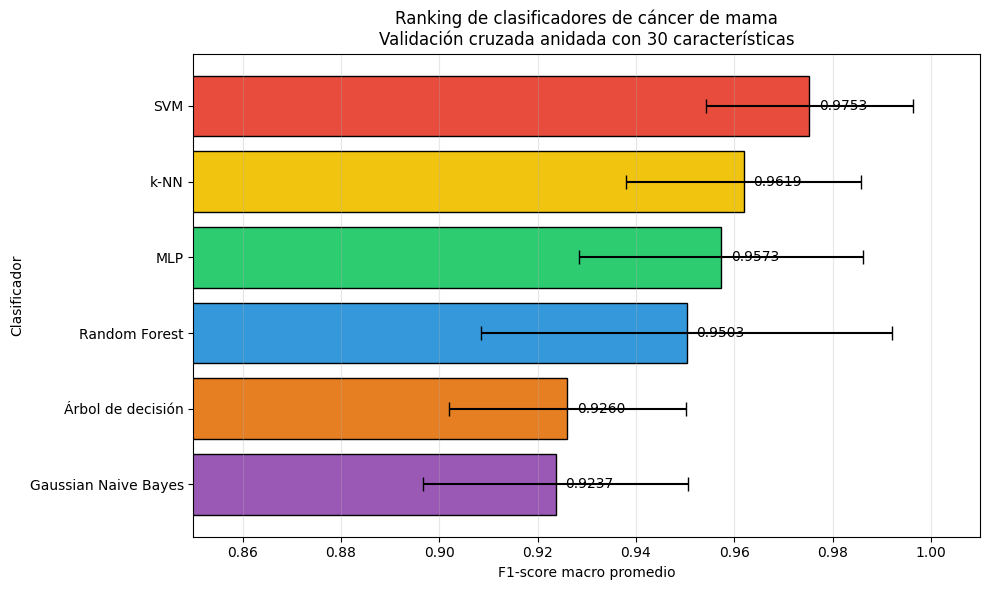

Mejor clasificador: SVM
Mejor F1 macro: 0.9753


In [ ]:
# Comparación de los seis clasificadores de cáncer de mama

resultados_comparacion = [
    {
        "modelo": "k-NN",
        "accuracy": 0.9648,
        "accuracy_std": 0.0219,
        "precision_macro": 0.9687,
        "precision_std": 0.0226,
        "recall_macro": 0.9576,
        "recall_std": 0.0259,
        "f1_macro": 0.9619,
        "f1_std": 0.0239,
        "mae": 0.0352,
        "mae_std": 0.0219
    },
    {
        "modelo": "Gaussian Naive Bayes",
        "accuracy": 0.9298,
        "accuracy_std": 0.0247,
        "precision_macro": 0.9346,
        "precision_std": 0.0272,
        "recall_macro": 0.9199,
        "recall_std": 0.0283,
        "f1_macro": 0.9237,
        "f1_std": 0.0270,
        "mae": 0.0702,
        "mae_std": 0.0247
    },
    {
        "modelo": "SVM",
        "accuracy": 0.9772,
        "accuracy_std": 0.0193,
        "precision_macro": 0.9780,
        "precision_std": 0.0187,
        "recall_macro": 0.9740,
        "recall_std": 0.0237,
        "f1_macro": 0.9753,
        "f1_std": 0.0210,
        "mae": 0.0228,
        "mae_std": 0.0193
    },
    {
        "modelo": "Árbol de decisión",
        "accuracy": 0.9315,
        "accuracy_std": 0.0214,
        "precision_macro": 0.9311,
        "precision_std": 0.0212,
        "recall_macro": 0.9242,
        "recall_std": 0.0285,
        "f1_macro": 0.9260,
        "f1_std": 0.0241,
        "mae": 0.0685,
        "mae_std": 0.0214
    },
    {
        "modelo": "Random Forest",
        "accuracy": 0.9544,
        "accuracy_std": 0.0370,
        "precision_macro": 0.9545,
        "precision_std": 0.0356,
        "recall_macro": 0.9481,
        "recall_std": 0.0454,
        "f1_macro": 0.9503,
        "f1_std": 0.0417,
        "mae": 0.0456,
        "mae_std": 0.0370
    },
    {
        "modelo": "MLP",
        "accuracy": 0.9613,
        "accuracy_std": 0.0246,
        "precision_macro": 0.9689,
        "precision_std": 0.0169,
        "recall_macro": 0.9508,
        "recall_std": 0.0345,
        "f1_macro": 0.9573,
        "f1_std": 0.0288,
        "mae": 0.0387,
        "mae_std": 0.0246
    }
]

tabla_comparacion = pd.DataFrame(resultados_comparacion)

# Ordenar por F1 macro de mayor a menor
ranking_modelos = tabla_comparacion.sort_values(
    by="f1_macro",
    ascending=False
).reset_index(drop=True)

ranking_modelos.index = ranking_modelos.index + 1
ranking_modelos.index.name = "posición"

# Tabla con promedio ± desviación estándar
tabla_formateada = pd.DataFrame({
    "Modelo": ranking_modelos["modelo"],
    "Accuracy": ranking_modelos.apply(
        lambda fila:
        f"{fila['accuracy']:.4f} ± {fila['accuracy_std']:.4f}",
        axis=1
    ),
    "Precision macro": ranking_modelos.apply(
        lambda fila:
        f"{fila['precision_macro']:.4f} ± {fila['precision_std']:.4f}",
        axis=1
    ),
    "Recall macro": ranking_modelos.apply(
        lambda fila:
        f"{fila['recall_macro']:.4f} ± {fila['recall_std']:.4f}",
        axis=1
    ),
    "F1 macro": ranking_modelos.apply(
        lambda fila:
        f"{fila['f1_macro']:.4f} ± {fila['f1_std']:.4f}",
        axis=1
    ),
    "MAE": ranking_modelos.apply(
        lambda fila:
        f"{fila['mae']:.4f} ± {fila['mae_std']:.4f}",
        axis=1
    )
})

tabla_formateada.index = ranking_modelos.index
tabla_formateada.index.name = "Posición"

print("Ranking de clasificadores por F1 macro:")
display(tabla_formateada)

# Gráfica del ranking
ranking_grafica = ranking_modelos.sort_values(
    by="f1_macro",
    ascending=True
)

plt.figure(figsize=(10, 6))

barras = plt.barh(
    ranking_grafica["modelo"],
    ranking_grafica["f1_macro"],
    xerr=ranking_grafica["f1_std"],
    color=[
        "#9b59b6",
        "#e67e22",
        "#3498db",
        "#2ecc71",
        "#f1c40f",
        "#e74c3c"
    ],
    edgecolor="black",
    capsize=5
)

plt.xlim(0.85, 1.01)
plt.xlabel("F1-score macro promedio")
plt.ylabel("Clasificador")
plt.title(
    "Ranking de clasificadores de cáncer de mama\n"
    "Validación cruzada anidada con 30 características"
)
plt.grid(axis="x", alpha=0.3)

for barra, valor in zip(
    barras,
    ranking_grafica["f1_macro"]
):
    plt.text(
        valor + 0.002,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.4f}",
        va="center"
    )

plt.tight_layout()
plt.show()

print(
    "Mejor clasificador:",
    ranking_modelos.iloc[0]["modelo"]
)
print(
    "Mejor F1 macro:",
    f"{ranking_modelos.iloc[0]['f1_macro']:.4f}"
)

### Análisis comparativo de los clasificadores

SVM obtuvo el mejor desempeño general con un F1 macro promedio de 0.9753, además de la mayor accuracy, precisión y recall, y el menor MAE. Su configuración con kernel RBF permitió construir una separación no lineal flexible en el espacio de 30 dimensiones. El escalado dentro del pipeline también favoreció su funcionamiento, ya que SVM es sensible a las diferencias de magnitud entre características.

k-NN ocupó el segundo lugar con un F1 macro de 0.9619. Su buen desempeño indica que, después del escalado, las muestras de una misma clase tienden a encontrarse cerca entre sí. No obstante, su rendimiento depende de la selección del número de vecinos, la métrica de distancia y la ponderación.

MLP alcanzó el tercer lugar con un F1 macro de 0.9573. La red neuronal pudo aprender relaciones entre las características mediante una capa oculta de 100 neuronas. Sin embargo, su desempeño fue ligeramente inferior al de SVM y presentó una mayor cantidad de casos malignos clasificados como benignos. Además, su entrenamiento depende de la inicialización, la tasa de aprendizaje, la regularización y el criterio de parada.

Random Forest obtuvo un F1 macro de 0.9503 y presentó la mayor desviación estándar entre los modelos principales. Aunque la combinación de numerosos árboles reduce el riesgo de sobreajuste respecto a un árbol individual, algunos folds resultaron considerablemente más difíciles. Sus variables más importantes estuvieron relacionadas con el tamaño y la irregularidad del tumor.

El árbol de decisión obtuvo un F1 macro de 0.9260. Su principal ventaja es la interpretabilidad, ya que permite observar las reglas y umbrales utilizados. Sin embargo, sus divisiones rectangulares y su sensibilidad a pequeñas variaciones en los datos limitaron su capacidad de generalización.

Gaussian Naive Bayes presentó el F1 macro más bajo, con 0.9237. Este resultado puede relacionarse con su supuesto de independencia condicional entre características, que no se cumple completamente en esta base. Variables como radio, perímetro y área se encuentran fuertemente relacionadas, lo que reduce la adecuación de dicho supuesto.

En general, los modelos sensibles a la geometría de los datos, especialmente SVM y k-NN, fueron los más competitivos después del escalado. Las fronteras dibujadas en el plano PCA ayudan a observar el solapamiento de las clases, pero corresponden a modelos adicionales entrenados con solo dos componentes. Por ello, no deben utilizarse para explicar completamente el comportamiento de los modelos evaluados con las 30 características originales. Además, las barras de error se superponen en varios casos, por lo que diferencias pequeñas entre modelos deben interpretarse con cautela.

---

## Comparación de los métodos no supervisados

K-means y clustering jerárquico se comparan principalmente mediante el coeficiente de silueta. Las etiquetas reales no se utilizaron durante el entrenamiento; únicamente se emplearon después para interpretar los agrupamientos mediante ARI y NMI.

Comparación de métodos no supervisados:


,Método,Configuración final,Espacio de ajuste,Coeficiente de silueta,ARI,NMI
Posición,,,,,,
1,Clustering jerárquico,"k=2, linkage=average, métrica=cosine",30 características escaladas,0.4687,0.7796,0.6816
2,K-means,k=2,30 características escaladas,0.3450,0.6707,0.5546


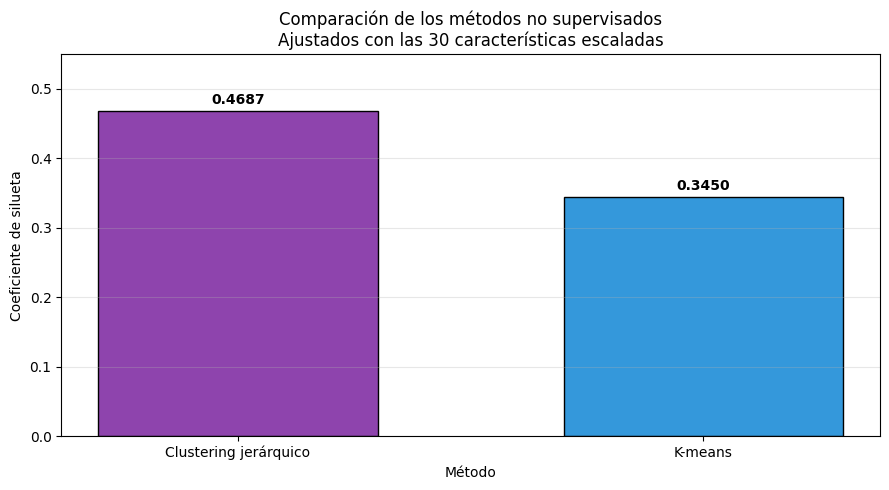

Mejor agrupamiento según silueta: Clustering jerárquico
Mejor coeficiente de silueta: 0.4687


In [ ]:
# Comparación de los métodos de clustering

resultados_clustering = pd.DataFrame({
    "Método": [
        "Clustering jerárquico",
        "K-means"
    ],
    "Configuración final": [
        "k=2, linkage=average, métrica=cosine",
        "k=2"
    ],
    "Espacio de ajuste": [
        "30 características escaladas",
        "30 características escaladas"
    ],
    "Coeficiente de silueta": [
        0.468734,
        0.344974
    ],
    "ARI": [
        0.7796,
        0.6707
    ],
    "NMI": [
        0.6816,
        0.5546
    ]
})

resultados_clustering = resultados_clustering.sort_values(
    by="Coeficiente de silueta",
    ascending=False
).reset_index(drop=True)

resultados_clustering.index = resultados_clustering.index + 1
resultados_clustering.index.name = "Posición"

print("Comparación de métodos no supervisados:")
display(resultados_clustering.round(4))

# Gráfica del coeficiente de silueta
plt.figure(figsize=(9, 5))

barras = plt.bar(
    resultados_clustering["Método"],
    resultados_clustering["Coeficiente de silueta"],
    color=["#8e44ad", "#3498db"],
    edgecolor="black",
    width=0.6
)

plt.ylim(0, 0.55)
plt.ylabel("Coeficiente de silueta")
plt.xlabel("Método")
plt.title(
    "Comparación de los métodos no supervisados\n"
    "Ajustados con las 30 características escaladas"
)
plt.grid(axis="y", alpha=0.3)

for barra, valor in zip(
    barras,
    resultados_clustering["Coeficiente de silueta"]
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.01,
        f"{valor:.4f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

print(
    "Mejor agrupamiento según silueta:",
    resultados_clustering.iloc[0]["Método"]
)

print(
    "Mejor coeficiente de silueta:",
    f"{resultados_clustering.iloc[0]['Coeficiente de silueta']:.4f}"
)

### Interpretación de los métodos no supervisados

El clustering jerárquico obtuvo el mejor resultado con un coeficiente de silueta de 0.4687, superior al valor de 0.3450 obtenido por K-means. Esto indica que los grupos generados por el método jerárquico presentan mayor cohesión interna y una separación más clara entre sí, aunque el valor de silueta también muestra que la estructura de agrupamiento no es perfecta.

La configuración final del clustering jerárquico utilizó dos grupos, enlace promedio y distancia coseno. Esta combinación también obtuvo un ARI de 0.7796 y un NMI de 0.6816, lo que muestra una correspondencia considerable entre los grupos encontrados y los diagnósticos reales. Las etiquetas reales no se utilizaron para entrenar el algoritmo, sino únicamente para interpretar posteriormente sus resultados.

K-means también seleccionó dos grupos, pero obtuvo una silueta de 0.3450, un ARI de 0.6707 y un NMI de 0.5546. Su menor desempeño puede explicarse porque K-means representa cada grupo mediante un centroide y funciona mejor cuando los grupos tienen formas aproximadamente esféricas y tamaños similares. La estructura de la base de cáncer de mama no cumple completamente estas condiciones.

Ambos métodos se ajustaron utilizando las 30 características escaladas. Los agrupamientos mostrados anteriormente en el plano PCA son únicamente una representación visual de los resultados. PC1 y PC2 explican conjuntamente el 63.24 % de la varianza, por lo que la separación observada en dos dimensiones no contiene toda la información utilizada durante el ajuste.

En conclusión, el clustering jerárquico fue el mejor método no supervisado para esta base, tanto por su coeficiente de silueta como por su mayor correspondencia con las clases reales. Sin embargo, estos resultados no deben compararse directamente con el F1-score de los clasificadores, ya que el clustering se realizó sin utilizar las etiquetas.